# LSTM + XGBoost Precipitation Forecasting - Retuned XGBoost Configuration

This notebook is derived from `runs/static/LSTM_XGBoost_Ensemble_Precipitation_STATIC.ipynb`.
It runs the **same pipeline, in the same order, with the same code**:

1. load the daily precipitation record
2. Box-Cox transform, lambda estimated on the training portion only
3. Min-Max scaling fitted on the training portion
4. chronological split, then window each half separately
5. build and train the LSTM
6. train XGBoost
7. combine the two with inverse-RMSE weighting
8. evaluate, then save artifacts

**What is fixed.** Every LSTM value, every shared preprocessing value (Box-Cox lambda, scaler,
window size, split point, series length, random seed) and the entire ensemble weighting step are
held at the values the reference pipeline uses. The configuration cell below declares those as
`FROZEN_KEYS` and the notebook raises an error if any of them differs.

**What is free.** The XGBoost hyperparameters only.

**What is added.** Evaluation, not modelling. The existing metrics are kept exactly as they are and
joined by a predictability ceiling, event-detection scores, skill scores against reference
forecasts, and an accumulated seven-day view. None of these change a single prediction; they change
only what is measured about them.

Artifacts are written to `models/v2_retuned/`. The notebook hashes `models/v2_static/` on entry and
re-checks it at the end, so the artifacts the deployed site loads cannot be touched by this run.


In [1]:
import math
import time
import json
import joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox, skew, kurtosis, pearsonr
from scipy.special import inv_boxcox
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    explained_variance_score,
)
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout, Input

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Imports ready.")


Imports ready.


In [2]:
# ---------------------------------------------------------------------------
# Additional imports used only by the sweep and extended-evaluation sections.
# The cell above is the reference pipeline's import cell, copied unchanged.
# ---------------------------------------------------------------------------
import hashlib
from collections import OrderedDict

from sklearn.metrics import roc_auc_score, average_precision_score

print("Extra imports ready.")


Extra imports ready.


In [3]:
# ---------------------------------------------------------------------------
# Path fix -- this notebook now lives in a subfolder (runs/...), but every
# path below is written relative to the repo root (2619492.csv, models/, ...).
# Walk up to the repo root and chdir there so everything resolves unchanged.
# Safe to re-run: once at the root it stays there.
# ---------------------------------------------------------------------------
import os
from pathlib import Path

_start = Path.cwd()
for _cand in [_start, *_start.parents]:
    if (_cand / "2619492.csv").exists() and (_cand / "streamlit_dashboard").is_dir():
        os.chdir(_cand)
        break
else:
    raise RuntimeError(f"Could not find repo root (looked for 2619492.csv) starting from {_start}")

print(f"Working directory set to repo root: {Path.cwd()}")


Working directory set to repo root: C:\Users\Dell\Desktop\Thesis


In [4]:
# ---------------------------------------------------------------------------
# Box-Cox transform helpers 
# ---------------------------------------------------------------------------
def boxcox1p(data):
    p1data = data + 1
    bcdata, bclambda = boxcox(p1data)
    return bcdata, bclambda

def inv_boxcox1p(bcdata, bclambda):
    return inv_boxcox(bcdata, bclambda) - 1


def split_sequences(series, window):
    """Sliding window: x[i] = series[i:i+window], y[i] = series[i+window]."""
    x, y = [], []
    for i in range(len(series)):
        end = i + window
        if end > len(series) - 1:
            break
        x.append(series[i:end])
        y.append(series[end])
    return np.array(x), np.array(y)


def safe_mape(y_true, y_pred, min_actual=0.1):
    """Mean absolute percentage error, computed only on days with at least
    min_actual inches of observed rain. Days at or near zero are excluded,
    since dividing by a near-zero actual value produces a huge or undefined
    percentage that would dominate the average without saying anything
    useful. min_actual=0.1 matches this dataset's recording precision
    (values are reported to the nearest 0.1 inch).
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true >= min_actual
    if mask.sum() == 0:
        return float('nan'), 0
    pct_errors = np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
    return float(np.mean(pct_errors) * 100.0), int(mask.sum())


def compute_sample_weights(y_boxcox, lambda_value, floor=0.01):
    """Heavier rain days get more weight during XGBoost training so the
    model is not dominated by the large share of zero/near-zero days."""
    y_orig = inv_boxcox1p(np.asarray(y_boxcox, dtype=float), lambda_value)
    y_orig = np.maximum(y_orig, 0.0)
    return np.sqrt(y_orig + floor)


# ---------------------------------------------------------------------------
# Extra evaluation metrics
# ---------------------------------------------------------------------------
def prediction_bias(y_true, y_pred):
    """Mean (signed) error: mean(pred - true). Positive means the model
    over-predicts on average, negative means it under-predicts. Unlike MAE
    this does not take an absolute value, so it reveals systematic bias
    that MAE/RMSE hide."""
    return float(np.mean(np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)))


def residual_statistics(y_true, y_pred):
    """Descriptive statistics of the residual (pred - true) distribution."""
    resid = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return {
        'mean': float(np.mean(resid)),
        'std': float(np.std(resid)),
        'skew': float(skew(resid)),
        'kurtosis': float(kurtosis(resid)),
        'min': float(np.min(resid)),
        'max': float(np.max(resid)),
    }


def improvement_percentage(baseline_value, new_value):
    """Percent reduction of new_value relative to baseline_value (positive
    = improvement, e.g. lower RMSE/MAE/MAPE)."""
    if baseline_value == 0:
        return float('nan')
    return float((baseline_value - new_value) / baseline_value * 100.0)


RAIN_INTENSITY_BINS = [-np.inf, 1e-9, 0.2, 0.5, np.inf]
RAIN_INTENSITY_LABELS = ['No Rain (0 in)', 'Light (0-0.2 in)', 'Moderate (0.2-0.5 in)', 'Heavy (>0.5 in)']

def rainfall_intensity_performance(y_true, y_pred):
    """RMSE/MAE per rainfall-intensity bucket. MAPE is only meaningful for
    buckets with nonzero actuals, so it is left out of the No Rain row."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    buckets = np.asarray(pd.cut(y_true, bins=RAIN_INTENSITY_BINS, labels=RAIN_INTENSITY_LABELS))
    rows = []
    for label in RAIN_INTENSITY_LABELS:
        mask = (buckets == label)
        n = int(mask.sum())
        if n == 0:
            rows.append({'Intensity': label, 'N': 0, 'RMSE': float('nan'), 'MAE': float('nan'), 'MAPE (%)': float('nan')})
            continue
        rmse_b = math.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))
        mae_b = mean_absolute_error(y_true[mask], y_pred[mask])
        if label == 'No Rain (0 in)':
            mape_b = float('nan')
        else:
            mape_b, _ = safe_mape(y_true[mask], y_pred[mask], min_actual=1e-9)
        rows.append({'Intensity': label, 'N': n, 'RMSE': rmse_b, 'MAE': mae_b, 'MAPE (%)': mape_b})
    return pd.DataFrame(rows)


def evaluate_all(y_true, y_pred, label):
    """One consolidated evaluation: RMSE, MAE, MAPE, R2, Pearson r,
    explained variance, and prediction bias."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape, mape_n = safe_mape(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    corr, _ = pearsonr(y_true, y_pred)
    expl_var = explained_variance_score(y_true, y_pred)
    bias = prediction_bias(y_true, y_pred)
    resid_stats = residual_statistics(y_true, y_pred)
    result = {
        'label': label,
        'rmse': rmse,
        'mae': mae,
        'mape': mape,
        'mape_n': mape_n,
        'r2': r2,
        'pearson_r': float(corr),
        'explained_variance': float(expl_var),
        'bias': bias,
        'residual_stats': resid_stats,
    }
    print(f"\n{label} evaluation:")
    print(f"  RMSE:                {rmse:.4f}")
    print(f"  MAE:                 {mae:.4f}")
    print(f"  MAPE:                {mape:.2f}% (on {mape_n} days >= 0.1 in)")
    print(f"  R2:                  {r2:.4f}")
    print(f"  Pearson r:           {corr:.4f}")
    print(f"  Explained Variance:  {expl_var:.4f}")
    print(f"  Prediction Bias:     {bias:+.4f} in (mean error, pred - true)")
    print(f"  Residual std/skew/kurtosis: {resid_stats['std']:.4f} / {resid_stats['skew']:.4f} / {resid_stats['kurtosis']:.4f}")
    return result

print("Utility functions defined.")


Utility functions defined.


In [5]:
# ---------------------------------------------------------------------------
# Prove, rather than assert, that the helper cell above is the reference
# pipeline's helper cell. The source is read back out of the reference
# notebook, executed in an isolated namespace, and the three metric functions
# this notebook depends on are required to return identical results on a fixed
# sample. A drift on either side fails here instead of silently changing a
# reported number.
# ---------------------------------------------------------------------------
STATIC_NB_PATH = Path("runs/static/LSTM_XGBoost_Ensemble_Precipitation_STATIC.ipynb")
_static_cells = json.loads(STATIC_NB_PATH.read_text(encoding="utf-8"))["cells"]
_helper_src = next("".join(c["source"]) for c in _static_cells
                   if c["cell_type"] == "code" and "def evaluate_all" in "".join(c["source"]))
HELPER_CELL_SHA256 = hashlib.sha256(_helper_src.encode("utf-8")).hexdigest()

_ref = {}
exec(_helper_src, dict(globals()), _ref)

_rng = np.random.default_rng(0)
_yt = np.abs(_rng.normal(2.0, 5.0, 500))
_yp = np.abs(_rng.normal(2.0, 0.4, 500))

assert _ref["safe_mape"](_yt, _yp) == safe_mape(_yt, _yp)
pd.testing.assert_frame_equal(_ref["rainfall_intensity_performance"](_yt, _yp),
                              rainfall_intensity_performance(_yt, _yp))
_a = {k: v for k, v in _ref["evaluate_all"](_yt, _yp, "ref").items() if k != "label"}
_b = {k: v for k, v in evaluate_all(_yt, _yp, "ref").items() if k != "label"}
assert _a == _b, "evaluate_all diverged from the reference implementation"

print("Verbatim-reuse check PASSED.")
print(f"  reference helper cell sha256: {HELPER_CELL_SHA256}")


Utility functions defined.

ref evaluation:
  RMSE:                4.0508
  MAE:                 2.9252
  MAPE:                110.30% (on 495 days >= 0.1 in)
  R2:                  -0.4955
  Pearson r:           -0.0154
  Explained Variance:  -0.0163
  Prediction Bias:     -2.2929 in (mean error, pred - true)
  Residual std/skew/kurtosis: 3.3394 / -1.0218 / 0.9388

ref evaluation:
  RMSE:                4.0508
  MAE:                 2.9252
  MAPE:                110.30% (on 495 days >= 0.1 in)
  R2:                  -0.4955
  Pearson r:           -0.0154
  Explained Variance:  -0.0163
  Prediction Bias:     -2.2929 in (mean error, pred - true)
  Residual std/skew/kurtosis: 3.3394 / -1.0218 / 0.9388
Verbatim-reuse check PASSED.
  reference helper cell sha256: 4c1fd4ee6502d87d64b6b743049be341b5f8098a15244e1ad9cc0fa2f26f508b


In [6]:
# ---------------------------------------------------------------------------
# Additional evaluation helpers. These measure the pipeline; none of them
# alters a prediction. Nothing defined above is shadowed or replaced.
# ---------------------------------------------------------------------------
def compute_sample_weights_p(y_boxcox, lambda_value, power=0.5, floor=0.01):
    """Generalisation of compute_sample_weights to an arbitrary exponent.
    At power=0.5, floor=0.01 this reduces exactly to the original."""
    y_orig = inv_boxcox1p(np.asarray(y_boxcox, dtype=float), lambda_value)
    y_orig = np.maximum(y_orig, 0.0)
    if power == 0.5:
        # Take the identical code path as the original, not an equivalent one.
        # np.power(x, 0.5) and np.sqrt(x) can differ in the last bit, which is
        # enough to move a tree split and shift the reported RMSE.
        return np.sqrt(y_orig + floor)
    return np.power(y_orig + floor, power)


def contingency_counts(y_true, y_pred, obs_threshold, pred_threshold=None):
    """2x2 contingency table for 'exceeds threshold' events.
    pred_threshold defaults to obs_threshold (the raw, uncalibrated case)."""
    t = obs_threshold if pred_threshold is None else pred_threshold
    obs = np.asarray(y_true, dtype=float) > obs_threshold
    fct = np.asarray(y_pred, dtype=float) > t
    a = int(np.sum(obs & fct))          # hits
    b = int(np.sum(~obs & fct))         # false alarms
    c = int(np.sum(obs & ~fct))         # misses
    d = int(np.sum(~obs & ~fct))        # correct negatives
    n = a + b + c + d
    return {'a_hits': a, 'b_false_alarms': b, 'c_misses': c, 'd_correct_neg': d, 'n': n,
            'base_rate': (a + c) / n if n else float('nan'),
            'forecast_rate': (a + b) / n if n else float('nan'),
            'pred_threshold': float(t)}


def _safe_div(num, den):
    """Undefined stays undefined. A degenerate forecast must never be scored
    as a perfect one, or as a zero, by an accidental 0/0."""
    return float(num) / float(den) if den else float('nan')


def event_detection_metrics(y_true, y_pred, obs_threshold, pred_threshold=None):
    """Contingency counts plus POD, FAR, CSI, frequency bias, HSS and ETS."""
    k = contingency_counts(y_true, y_pred, obs_threshold, pred_threshold)
    a, b, c, d, n = k['a_hits'], k['b_false_alarms'], k['c_misses'], k['d_correct_neg'], k['n']
    a_ref = (a + b) * (a + c) / n if n else float('nan')
    hss_den = (a + c) * (c + d) + (a + b) * (b + d)
    out = dict(k)
    out.update({
        'POD': _safe_div(a, a + c),
        'FAR': _safe_div(b, a + b),
        'CSI': _safe_div(a, a + b + c),
        'BIAS': _safe_div(a + b, a + c),
        'HSS': _safe_div(2 * (a * d - b * c), hss_den),
        'ETS': _safe_div(a - a_ref, a + b + c - a_ref),
    })
    return out


def calibrated_pred_threshold(y_val_true, y_val_pred, obs_threshold):
    """Frequency-bias-1 calibration: the forecast threshold at which the
    forecast event rate equals the observed event rate on the validation
    slice. Fitted on validation only; never on the test set."""
    base = float(np.mean(np.asarray(y_val_true, dtype=float) > obs_threshold))
    if base <= 0.0 or base >= 1.0:
        return float('nan')
    return float(np.quantile(np.asarray(y_val_pred, dtype=float), 1.0 - base))


def roc_auc(y_true, y_pred, obs_threshold):
    """Area under the ROC curve for 'exceeds threshold', scoring by the raw
    forecast value. Equivalent to the Mann-Whitney U statistic normalised by
    n_pos * n_neg, so it measures ranking only and is unaffected by any
    increasing transform of the forecast."""
    lab = (np.asarray(y_true, dtype=float) > obs_threshold).astype(int)
    if lab.min() == lab.max():
        return float('nan')
    return float(roc_auc_score(lab, np.asarray(y_pred, dtype=float)))


def average_precision(y_true, y_pred, obs_threshold):
    lab = (np.asarray(y_true, dtype=float) > obs_threshold).astype(int)
    if lab.min() == lab.max():
        return float('nan')
    return float(average_precision_score(lab, np.asarray(y_pred, dtype=float)))


def skill_score(y_true, y_pred, y_ref, metric='mse'):
    """1 - M(model) / M(reference). Zero means no better than the reference."""
    yt = np.asarray(y_true, dtype=float)
    if metric == 'mae':
        m = np.mean(np.abs(yt - np.asarray(y_pred, dtype=float)))
        r = np.mean(np.abs(yt - np.asarray(y_ref, dtype=float)))
    else:
        m = np.mean((yt - np.asarray(y_pred, dtype=float)) ** 2)
        r = np.mean((yt - np.asarray(y_ref, dtype=float)) ** 2)
        if metric == 'rmse':
            m, r = math.sqrt(m), math.sqrt(r)
    return _safe_div(r - m, r)


def mase(y_true, y_pred, y_scale_series, m=1):
    """Mean absolute scaled error. The denominator is the mean absolute
    m-step difference of the series supplied, so which series is passed
    changes the meaning and must be reported alongside the number."""
    s = np.asarray(y_scale_series, dtype=float)
    q = np.mean(np.abs(s[m:] - s[:-m]))
    return _safe_div(np.mean(np.abs(np.asarray(y_true, dtype=float)
                                    - np.asarray(y_pred, dtype=float))), q)


# The generalised weighting function must reduce exactly to the original at the
# reference exponent, or a "no change" run would not in fact be a no-change run.
_LAM_CHK = -1.4386915682381394
_wchk = np.linspace(0.0, -1.0 / _LAM_CHK * 0.999, 64)   # inside the transform's range
_w_orig = compute_sample_weights(_wchk, _LAM_CHK)
_w_gen = compute_sample_weights_p(_wchk, _LAM_CHK, 0.5, 0.01)
assert np.array_equal(_w_orig, _w_gen), "compute_sample_weights_p diverged at power=0.5"

print("Extended evaluation helpers defined.")
print("  compute_sample_weights_p verified identical to the original at power=0.5.")


Extended evaluation helpers defined.
  compute_sample_weights_p verified identical to the original at power=0.5.


## Configuration: what is fixed, what changed, and why

The two dictionaries below are the whole story of this notebook.

`BASELINE_CONFIG` is a literal transcription of the reference pipeline's configuration cell.
`CONFIG` is what this run actually executes. The diff table that follows is rendered from the two
dictionaries directly, so it can never drift from what ran.

`CHANGE_RATIONALE` is written **before** the sweeps below are executed. It is the hypothesis
register: each entry states what a change is expected to buy, so a change that fails to deliver is
visible as a failed prediction rather than quietly dropped.


In [7]:
# ---------------------------------------------------------------------------
# BASELINE_CONFIG is a literal transcription of the reference pipeline's
# configuration. It is what every change in this notebook is measured
# against, and it is never written to.
# ---------------------------------------------------------------------------
TRAIN_DATA_CANDIDATES = ['2619492.csv', 'Data/2619492.csv', 'content/2619492.csv']

BASELINE_CONFIG = OrderedDict([
    # ---- frozen: shared with the LSTM, or defines the experiment itself ----
    ('DATA_CUTOFF',                  9058),
    ('TOTAL_DATA_LENGTH',            10988),
    ('WINDOW_SIZE',                  70),
    ('RANDOM_STATE',                 42),
    ('LSTM_UNITS_LAYER1',            32),
    ('LSTM_UNITS_LAYER2',            32),
    ('LSTM_DENSE_UNITS',             16),
    ('LSTM_DROPOUT',                 0.5),
    ('LSTM_EPOCHS',                  100),
    ('LSTM_BATCH_SIZE',              60),
    ('LSTM_LEARNING_RATE',           1e-7),
    ('LSTM_MOMENTUM',                0.9),
    # ---- frozen: the ensemble weighting step ----
    ('ENSEMBLE_VALIDATION_FRACTION', 0.08),
    ('ENSEMBLE_STRATEGY',            'inverse_rmse'),
    # ---- free: XGBoost ----
    ('XGB_OBJECTIVE',                'reg:pseudohubererror'),
    ('XGB_HUBER_SLOPE',              0.5),
    ('XGB_TWEEDIE_VARIANCE_POWER',   1.5),   # only read when the objective is tweedie
    ('XGB_N_ESTIMATORS',             1000),
    ('XGB_MAX_DEPTH',                2),
    ('XGB_LEARNING_RATE',            0.05),
    ('XGB_SUBSAMPLE',                0.7),
    ('XGB_COLSAMPLE_BYTREE',         0.6),
    ('XGB_MIN_CHILD_WEIGHT',         8),
    ('XGB_GAMMA',                    0.0),
    ('XGB_REG_ALPHA',                0.05),
    ('XGB_REG_LAMBDA',               1.0),
    ('XGB_EARLY_STOPPING_ROUNDS',    60),
    ('XGB_VAL_FRACTION',             0.12),
    ('XGB_SAMPLE_WEIGHT_POWER',      0.5),
    ('XGB_SAMPLE_WEIGHT_FLOOR',      0.01),
])

# Keys this notebook is not permitted to change. Enforced in the next cell.
FROZEN_KEYS = frozenset([k for k in BASELINE_CONFIG if k.startswith('LSTM_')] + [
    'DATA_CUTOFF', 'TOTAL_DATA_LENGTH', 'WINDOW_SIZE', 'RANDOM_STATE',
    'ENSEMBLE_VALIDATION_FRACTION', 'ENSEMBLE_STRATEGY',
])

SCOPE_OF = {k: ('frozen' if k in FROZEN_KEYS else 'xgboost') for k in BASELINE_CONFIG}

# Reproduced baseline (fixed LSTM-only model, same dataset/split/preprocessing).
BASELINE_RMSE = 6.2009
BASELINE_MAE = 2.3244
BASELINE_MAPE = 81.10

# Results of the reference run, read from its saved metadata so the change
# ledger at the end has something to difference against without re-running it.
_ref_meta_path = Path("models") / "v2_static" / "metadata.json"
REFERENCE_RUN = json.loads(_ref_meta_path.read_text(encoding="utf-8"))
REFERENCE_EVAL = REFERENCE_RUN['evaluation']

print(f"Baseline configuration loaded: {len(BASELINE_CONFIG)} values, "
      f"{len(FROZEN_KEYS)} of them frozen.")
print(f"Reference run read from {_ref_meta_path}: "
      f"ensemble RMSE={REFERENCE_EVAL['ensemble']['rmse']:.4f}, "
      f"MAE={REFERENCE_EVAL['ensemble']['mae']:.4f}")


Baseline configuration loaded: 30 values, 14 of them frozen.
Reference run read from models\v2_static\metadata.json: ensemble RMSE=5.6419, MAE=2.6107


In [8]:
# ---------------------------------------------------------------------------
# CONFIG is what this run executes. It starts as a copy of the baseline; the
# sweeps below select the final XGBoost values on the validation slice and
# write them back here, after which the diff table is re-rendered.
#
# CHANGE_RATIONALE is written now, before any sweep has produced a number, so
# it reads as a hypothesis register rather than a post-hoc justification.
# ---------------------------------------------------------------------------
CONFIG = OrderedDict(BASELINE_CONFIG)

CHANGE_RATIONALE = {
    'XGB_HUBER_SLOPE':
        "The Huber slope caps how much a single large residual contributes to the gradient. "
        "Widening it lets rare heavy-rain days carry more influence, and those are the days "
        "where the discrimination measured further below is concentrated. Chosen by sweep X1.",
    'XGB_OBJECTIVE':
        "Compared against objectives built for zero-inflated non-negative targets. Chosen by X1.",
    'XGB_SAMPLE_WEIGHT_POWER':
        "Sets how strongly rain days outweigh dry days in the fit, so it is the direct control "
        "on the level the forecast settles at. Chosen by sweep X2.",
    'XGB_MAX_DEPTH':
        "Capacity to represent a threshold-like rule rather than a smooth response. Chosen by X3.",
    'XGB_MIN_CHILD_WEIGHT':
        "Evidence mass required before a split is allowed. Chosen by sweep X3.",
    'XGB_EARLY_STOPPING_ROUNDS':
        "Raised only alongside a deeper variant, so that variant is not halted prematurely.",
}

# Selection-rule constants, fixed here, before any sweep output exists.
SELECTION_RMSE_TOLERANCE = 0.01
EVENT_THRESHOLDS = (0.0, 0.5, 2.0, 5.0)
PRIMARY_AUC_THRESHOLDS = (2.0, 5.0)

# --- unpack to the module-level names the copied pipeline cells expect ---
DATA_CUTOFF = CONFIG['DATA_CUTOFF']
TOTAL_DATA_LENGTH = CONFIG['TOTAL_DATA_LENGTH']
WINDOW_SIZE = CONFIG['WINDOW_SIZE']
RANDOM_STATE = CONFIG['RANDOM_STATE']
ENSEMBLE_VALIDATION_FRACTION = CONFIG['ENSEMBLE_VALIDATION_FRACTION']
LSTM_UNITS_LAYER1 = CONFIG['LSTM_UNITS_LAYER1']
LSTM_UNITS_LAYER2 = CONFIG['LSTM_UNITS_LAYER2']
LSTM_DENSE_UNITS = CONFIG['LSTM_DENSE_UNITS']
LSTM_DROPOUT = CONFIG['LSTM_DROPOUT']
LSTM_EPOCHS = CONFIG['LSTM_EPOCHS']
LSTM_BATCH_SIZE = CONFIG['LSTM_BATCH_SIZE']
LSTM_LEARNING_RATE = CONFIG['LSTM_LEARNING_RATE']
LSTM_MOMENTUM = CONFIG['LSTM_MOMENTUM']

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)


def xgb_params_from(cfg):
    """The nine-key parameter dict the reference pipeline hands to XGBRegressor."""
    return {
        'n_estimators':     cfg['XGB_N_ESTIMATORS'],
        'max_depth':        cfg['XGB_MAX_DEPTH'],
        'learning_rate':    cfg['XGB_LEARNING_RATE'],
        'subsample':        cfg['XGB_SUBSAMPLE'],
        'colsample_bytree': cfg['XGB_COLSAMPLE_BYTREE'],
        'min_child_weight': cfg['XGB_MIN_CHILD_WEIGHT'],
        'gamma':            cfg['XGB_GAMMA'],
        'reg_alpha':        cfg['XGB_REG_ALPHA'],
        'reg_lambda':       cfg['XGB_REG_LAMBDA'],
    }


# --- output directory, and the guard protecting the deployed artifacts ---
MODEL_DIR = Path("models") / "v2_retuned"
assert MODEL_DIR.name != "v2_static", "This notebook must never write the deployed artifacts."
for _sub in ("", "sweeps", "predictions", "figures"):
    (MODEL_DIR / _sub).mkdir(parents=True, exist_ok=True)

STATIC_DIR = Path("models") / "v2_static"


def _dir_hashes(d):
    return {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
            for p in sorted(d.iterdir()) if p.is_file()}


STATIC_HASHES_AT_START = _dir_hashes(STATIC_DIR)

print(f"Output directory: {MODEL_DIR}")
print(f"Protected directory {STATIC_DIR} hashed at start ({len(STATIC_HASHES_AT_START)} files).")


Output directory: models\v2_retuned
Protected directory models\v2_static hashed at start (4 files).


In [9]:
# ---------------------------------------------------------------------------
# The change table. Rendered straight from the two dictionaries, so it cannot
# drift from what actually ran, and it fails loudly if a frozen value moved.
# ---------------------------------------------------------------------------
SHOW_UNCHANGED = False


def _fmt(v):
    return f"{v:g}" if isinstance(v, float) else str(v)


def config_diff(baseline, variant, rationale, selected_by=None):
    rows = []
    for k in baseline:
        changed = baseline[k] != variant[k]
        row = {
            'Parameter': k,
            'Baseline (v2_static)': _fmt(baseline[k]),
            'This run': _fmt(variant[k]),
            'Changed': 'YES' if changed else '',
            'Scope': SCOPE_OF[k],
            'Why changed': (rationale.get(k, '') if changed else ''),
        }
        if selected_by is not None:
            row['Selected by'] = selected_by.get(k, '') if changed else ''
        rows.append(row)
    df = pd.DataFrame(rows)
    return df.sort_values(['Changed', 'Scope', 'Parameter'],
                          ascending=[False, True, True]).reset_index(drop=True)


def render_config_diff(variant, rationale, selected_by=None, title="Configuration"):
    assert set(variant) == set(BASELINE_CONFIG), "configuration key set drifted"
    violations = [k for k in FROZEN_KEYS if variant[k] != BASELINE_CONFIG[k]]
    assert not violations, f"FROZEN values changed, which is out of scope: {violations}"

    df = config_diff(BASELINE_CONFIG, variant, rationale, selected_by)
    changed = df[df['Changed'] == 'YES']
    by_scope = changed['Scope'].value_counts().to_dict()
    scope_txt = ', '.join(f"{k}: {v}" for k, v in sorted(by_scope.items())) or 'none'

    print(f"=== {title} ===")
    print(f"{len(changed)} of {len(df)} configuration values changed "
          f"({scope_txt}). 0 frozen values changed.")
    print()
    shown = df if SHOW_UNCHANGED else (changed if len(changed) else df.head(0))
    if len(shown):
        with pd.option_context('display.max_colwidth', 78, 'display.width', 200):
            print(shown.to_string(index=False))
    else:
        print("(no departures from the baseline configuration)")
    if not SHOW_UNCHANGED:
        print()
        print(f"({len(df) - len(changed)} unchanged values not shown; "
              f"set SHOW_UNCHANGED = True to list them.)")
    return df


df_config_diff = render_config_diff(CONFIG, CHANGE_RATIONALE,
                                    title="Configuration at entry (before sweeps)")


=== Configuration at entry (before sweeps) ===
0 of 30 configuration values changed (none). 0 frozen values changed.

(no departures from the baseline configuration)

(30 unchanged values not shown; set SHOW_UNCHANGED = True to list them.)


In [10]:
# ---------------------------------------------------------------------------
# Load data and apply Box-Cox transform (lambda estimated on the training
# portion only, then applied to the whole series to avoid leakage)
# ---------------------------------------------------------------------------
csv_path = next((p for p in TRAIN_DATA_CANDIDATES if Path(p).exists()), None)
if csv_path is None:
    raise FileNotFoundError(f"Could not find training data. Searched: {TRAIN_DATA_CANDIDATES}")

rainfall = pd.read_csv(csv_path)
rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
rainfall = rainfall.set_index('DATE')
print(f"Loaded {len(rainfall)} records from {csv_path}")

_, lam_value = boxcox1p(rainfall.PRCP.iloc[:DATA_CUTOFF])
inv_data = boxcox(rainfall.PRCP.to_numpy() + 1, lmbda=lam_value)
print(f"Box-Cox lambda (fit on train only): {lam_value:.6f}")

# LSTM works on Min-Max scaled Box-Cox values (gradient descent needs a
# bounded scale). XGBoost is scale-invariant so it uses the Box-Cox values
# directly, unscaled -- this matches the exploratory notebook's design.
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(inv_data[:DATA_CUTOFF].reshape(-1, 1))
rain_data_scaled = scaler.transform(inv_data.reshape(-1, 1))[:, 0]

lstm_series = rain_data_scaled[:TOTAL_DATA_LENGTH]
xgb_series = inv_data[:TOTAL_DATA_LENGTH]

print(f"Series length used for modeling: {len(lstm_series)}")


Loaded 11323 records from 2619492.csv


Box-Cox lambda (fit on train only): -1.438692


Series length used for modeling: 10988


In [11]:
# ---------------------------------------------------------------------------
# Build LSTM and XGBoost feature/target arrays the same way the baseline
# code does: split the raw series into train/test at DATA_CUTOFF *first*,
# then window each half separately, with no lookback context borrowed
# across the cutoff. This means the first WINDOW_SIZE (70) days of the
# test period are consumed purely as context and are never scored -- the
# first scored test day is DATA_CUTOFF + WINDOW_SIZE, matching the
# baseline's own test-set construction exactly (previously this notebook
# windowed the full series continuously and scored from DATA_CUTOFF
# itself, which gave 70 more test days than the baseline's method can
# produce; see the panel change request for the measured effect of that
# difference).
# ---------------------------------------------------------------------------
lstm_train_series = lstm_series[:DATA_CUTOFF]
lstm_test_series = lstm_series[DATA_CUTOFF:]
xgb_train_series = xgb_series[:DATA_CUTOFF]
xgb_test_series = xgb_series[DATA_CUTOFF:]

x_train, y_train = split_sequences(lstm_train_series, WINDOW_SIZE)
x_test, y_test = split_sequences(lstm_test_series, WINDOW_SIZE)
x_train = x_train.reshape(-1, WINDOW_SIZE, 1)
x_test = x_test.reshape(-1, WINDOW_SIZE, 1)

x_train_lag, y_train_lag = split_sequences(xgb_train_series, WINDOW_SIZE)
x_test_lag, y_test_lag = split_sequences(xgb_test_series, WINDOW_SIZE)

print(f"LSTM   train/test: {x_train.shape} / {x_test.shape}")
print(f"XGBoost train/test: {x_train_lag.shape} / {x_test_lag.shape}")
assert len(x_test) == len(x_test_lag), "LSTM and XGBoost test sets must be the same length"


LSTM   train/test: (8988, 70, 1) / (1860, 70, 1)
XGBoost train/test: (8988, 70) / (1860, 70)


In [12]:
# ---------------------------------------------------------------------------
# LSTM model: fixed architecture, fixed hyperparameters
# ---------------------------------------------------------------------------
model = Sequential()
model.add(Input(shape=(WINDOW_SIZE, 1)))
model.add(LSTM(LSTM_UNITS_LAYER1, activation='tanh', return_sequences=True))
model.add(Dropout(LSTM_DROPOUT))
model.add(LSTM(LSTM_UNITS_LAYER2, activation='relu'))
model.add(Dropout(LSTM_DROPOUT))
model.add(Dense(LSTM_DENSE_UNITS, activation='relu'))
model.add(Dense(1, activation='relu'))

lr_schedule = tf.keras.callbacks.LearningRateScheduler(
    lambda epoch: LSTM_LEARNING_RATE * 10 ** (epoch / 40))
optimizer = tf.keras.optimizers.SGD(learning_rate=LSTM_LEARNING_RATE, momentum=LSTM_MOMENTUM)
model.compile(loss=tf.keras.losses.Huber(), optimizer=optimizer, metrics=["mean_squared_error"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 70, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 70, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,217 (51.63 KB)

 Trainable params: 13,217 (51.63 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
print("Training LSTM...")
lstm_train_start = time.time()
history = model.fit(
    x_train, y_train,
    epochs=LSTM_EPOCHS, batch_size=LSTM_BATCH_SIZE, verbose=1,
    validation_data=(x_train, y_train), callbacks=[lr_schedule],
)
lstm_train_seconds = time.time() - lstm_train_start
print(f"LSTM training complete in {lstm_train_seconds:.1f}s")


Training LSTM...


Epoch 1/100


  1/150 ━━━━━━━━━━━━━━━━━━━━ 6:28 3s/step - loss: 0.1392 - mean_squared_error: 0.2785

  3/150 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.1238 - mean_squared_error: 0.2475

  5/150 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.1303 - mean_squared_error: 0.2606

...

145/150 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0766 - mean_squared_error: 0.1531

147/150 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0764 - mean_squared_error: 0.1528

149/150 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0764 - mean_squared_error: 0.1528

150/150 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - loss: 0.0764 - mean_squared_error: 0.1528 - val_loss: 0.0751 - val_mean_squared_error: 0.1501 - learning_rate: 2.9854e-05


LSTM training complete in 724.2s


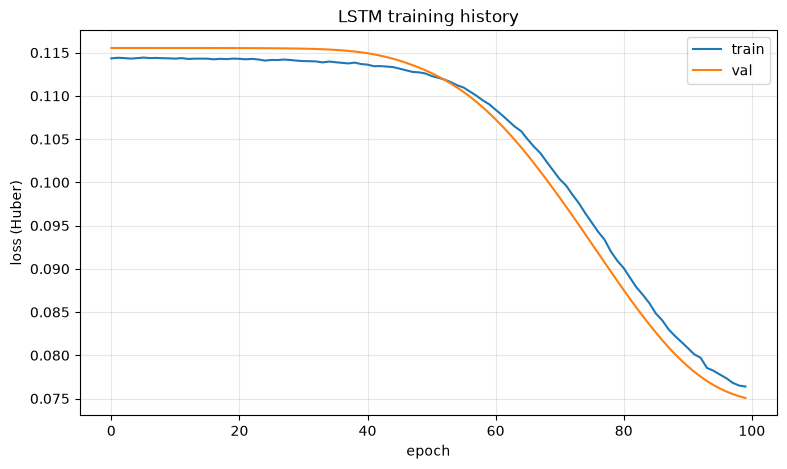

In [14]:
plt.figure(figsize=(9, 5))
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.xlabel('epoch')
plt.ylabel('loss (Huber)')
plt.title('LSTM training history')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [15]:
# ---------------------------------------------------------------------------
# Ground-truth test targets, in original precipitation units. Both models
# share the same test targets day for day, so there is a single true y_test_orig.
# ---------------------------------------------------------------------------
y_test_bc = scaler.inverse_transform(y_test.reshape(-1, 1))[:, 0]
y_test_orig = inv_boxcox1p(y_test_bc, lam_value)

y_test_lag_orig = inv_boxcox1p(y_test_lag, lam_value)
assert np.allclose(y_test_orig, y_test_lag_orig, atol=1e-6), "LSTM and XGBoost targets must match"


In [16]:
# ---------------------------------------------------------------------------
# LSTM evaluation
# ---------------------------------------------------------------------------
lstm_predict_start = time.time()
lstm_pred_scaled = model.predict(x_test, verbose=0)
lstm_predict_seconds = time.time() - lstm_predict_start

lstm_pred_bc = scaler.inverse_transform(lstm_pred_scaled)[:, 0]
lstm_pred_orig = inv_boxcox1p(lstm_pred_bc, lam_value)

lstm_eval = evaluate_all(y_test_orig, lstm_pred_orig, "LSTM (standalone)")
lstm_intensity = rainfall_intensity_performance(y_test_orig, lstm_pred_orig)
print("\nRainfall-Intensity Performance (LSTM):")
print(lstm_intensity.to_string(index=False))



LSTM (standalone) evaluation:
  RMSE:                5.9031
  MAE:                 2.2954
  MAPE:                78.11% (on 784 days >= 0.1 in)
  R2:                  -0.1355
  Pearson r:           -0.0070
  Explained Variance:  -0.0000
  Prediction Bias:     -2.0391 in (mean error, pred - true)
  Residual std/skew/kurtosis: 5.5398 / -4.5985 / 34.2711

Rainfall-Intensity Performance (LSTM):
            Intensity    N      RMSE      MAE  MAPE (%)
       No Rain (0 in) 1076  0.221702 0.221558       NaN
     Light (0-0.2 in)    0       NaN      NaN       NaN
Moderate (0.2-0.5 in)  184  0.182396 0.154048 36.976354
      Heavy (>0.5 in)  600 10.388763 6.671161 90.725907


## XGBoost sweeps

Three sweeps, each attached to a stated hypothesis about the next-day signal problem. The LSTM is
trained once, above, and every variant below reuses those same predictions - nothing in this section
retrains or otherwise touches it.

**Selection rule, fixed before any result below is produced:**

1. Every variant is scored on the **validation slice only**. The held-out test set is scored once, at
   the end, for the configuration that selection returns.
2. The criterion is computed on the **ensemble**, not on XGBoost in isolation. The ensemble is the
   deliverable, and a change can help one and hurt the other.
3. The primary criterion is mean validation AUC at the 2-inch and 5-inch thresholds - the quantity
   the existing metrics cannot see.
4. A variant is adopted only if it improves the primary criterion **and** does not worsen validation
   ensemble RMSE by more than `SELECTION_RMSE_TOLERANCE` (0.01 in).
5. Every variant is reported whether or not it is adopted, so the search is visible rather than only
   its winner.

A note on the slices: the early-stopping split and the ensemble-weighting split are both taken from
the end of the training block, as the reference pipeline takes them, so they overlap. That is a
property of the pipeline being reproduced, not a choice made here; it is recorded so the numbers are
read with it in mind.


In [17]:
# ---------------------------------------------------------------------------
# Sweep harness. Every variant is fitted on the training block and scored on
# the validation slice only; nothing here reads the test set.
#
# The validation slice is split in two. Ensemble weights are derived on the
# first half and the ensemble is scored on the second, so a variant is never
# scored on the data that chose its own weights.
# ---------------------------------------------------------------------------
def objective_extras(cfg):
    """Objective-specific keyword arguments for XGBRegressor."""
    obj = cfg['XGB_OBJECTIVE']
    if obj == 'reg:pseudohubererror':
        return {'huber_slope': cfg['XGB_HUBER_SLOPE']}
    if obj == 'reg:tweedie':
        return {'tweedie_variance_power': cfg.get('XGB_TWEEDIE_VARIANCE_POWER', 1.5)}
    return {}


_n_ens = max(256, int(len(x_train) * ENSEMBLE_VALIDATION_FRACTION))
_half = _n_ens // 2

ens_fit_lstm_x = x_train[-_n_ens:-_half]
ens_fit_xgb_x = x_train_lag[-_n_ens:-_half]
ens_fit_y_bc = y_train_lag[-_n_ens:-_half]

ens_score_lstm_x = x_train[-_half:]
ens_score_xgb_x = x_train_lag[-_half:]
ens_score_y_bc = y_train_lag[-_half:]

ens_fit_y_orig = inv_boxcox1p(ens_fit_y_bc, lam_value)
ens_score_y_orig = inv_boxcox1p(ens_score_y_bc, lam_value)

# The LSTM is trained once, above. Its validation predictions are computed
# once here and reused by every variant; no sweep retrains or alters it.
lstm_fit_pred = inv_boxcox1p(
    scaler.inverse_transform(model.predict(ens_fit_lstm_x, verbose=0))[:, 0], lam_value)
lstm_score_pred = inv_boxcox1p(
    scaler.inverse_transform(model.predict(ens_score_lstm_x, verbose=0))[:, 0], lam_value)

_es_n_val = max(256, int(len(x_train_lag) * CONFIG['XGB_VAL_FRACTION']))
_es_x_tr, _es_x_val = x_train_lag[:-_es_n_val], x_train_lag[-_es_n_val:]
_es_y_tr, _es_y_val = y_train_lag[:-_es_n_val], y_train_lag[-_es_n_val:]

print(f"Validation slices built: {len(ens_fit_y_orig)} rows to fit ensemble weights, "
      f"{len(ens_score_y_orig)} rows to score on.")
print(f"Early-stopping slice: {_es_n_val} rows.")
print(f"LSTM validation predictions cached (mean {lstm_score_pred.mean():.4f} in, "
      f"sd {lstm_score_pred.std():.4f} in).")


def run_xgb_variant(name, overrides):
    """Fit one XGBoost variant and score it, and the resulting ensemble, on
    the validation slice. Returns a flat dict of validation metrics."""
    cfg = OrderedDict(CONFIG)
    cfg.update(overrides)

    sw_tr = compute_sample_weights_p(_es_y_tr, lam_value,
                                     cfg['XGB_SAMPLE_WEIGHT_POWER'],
                                     cfg['XGB_SAMPLE_WEIGHT_FLOOR'])
    sw_val = compute_sample_weights_p(_es_y_val, lam_value,
                                      cfg['XGB_SAMPLE_WEIGHT_POWER'],
                                      cfg['XGB_SAMPLE_WEIGHT_FLOOR'])

    m = xgb.XGBRegressor(
        objective=cfg['XGB_OBJECTIVE'],
        eval_metric='rmse',
        random_state=cfg['RANDOM_STATE'],
        n_jobs=-1,
        tree_method='hist',
        early_stopping_rounds=cfg['XGB_EARLY_STOPPING_ROUNDS'],
        **objective_extras(cfg),
        **xgb_params_from(cfg),
    )
    t0 = time.time()
    m.fit(_es_x_tr, _es_y_tr, sample_weight=sw_tr,
          eval_set=[(_es_x_val, _es_y_val)], sample_weight_eval_set=[sw_val],
          verbose=False)
    fit_seconds = time.time() - t0
    trees = int(m.best_iteration + 1) if m.best_iteration is not None else cfg['XGB_N_ESTIMATORS']

    xgb_fit_pred = inv_boxcox1p(m.predict(ens_fit_xgb_x), lam_value)
    xgb_score_pred = inv_boxcox1p(m.predict(ens_score_xgb_x), lam_value)

    # Ensemble weights: the reference rule, unchanged, derived on the fit half.
    r_l = math.sqrt(mean_squared_error(ens_fit_y_orig, lstm_fit_pred))
    r_x = math.sqrt(mean_squared_error(ens_fit_y_orig, xgb_fit_pred))
    w_l = (1.0 / r_l) / ((1.0 / r_l) + (1.0 / r_x))
    w_x = 1.0 - w_l
    ens_score_pred = w_l * lstm_score_pred + w_x * xgb_score_pred

    row = {
        'Variant': name,
        'Trees': trees,
        'Fit s': round(fit_seconds, 2),
        'w_lstm': w_l,
        'XGB val RMSE': math.sqrt(mean_squared_error(ens_score_y_orig, xgb_score_pred)),
        'XGB val MAE': mean_absolute_error(ens_score_y_orig, xgb_score_pred),
        'ENS val RMSE': math.sqrt(mean_squared_error(ens_score_y_orig, ens_score_pred)),
        'ENS val MAE': mean_absolute_error(ens_score_y_orig, ens_score_pred),
        'ENS val R2': r2_score(ens_score_y_orig, ens_score_pred),
        'XGB pred sd': float(np.std(xgb_score_pred)),
    }
    for t in EVENT_THRESHOLDS:
        row[f'AUC>{t:g}'] = roc_auc(ens_score_y_orig, ens_score_pred, t)
    row['PRIMARY'] = float(np.nanmean([row[f'AUC>{t:g}'] for t in PRIMARY_AUC_THRESHOLDS]))
    row['_overrides'] = overrides
    return row


SWEEP_DISPLAY_COLS = ['Variant', 'Trees', 'w_lstm', 'XGB val RMSE', 'XGB val MAE',
                      'ENS val RMSE', 'ENS val MAE', 'ENS val R2', 'XGB pred sd',
                      'AUC>2', 'AUC>5', 'PRIMARY']


def show_sweep(rows, name):
    df = pd.DataFrame(rows)
    out = df[SWEEP_DISPLAY_COLS]
    print(out.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
    df.drop(columns=['_overrides']).to_csv(MODEL_DIR / 'sweeps' / f'{name}.csv', index=False)
    return df


print("Sweep harness ready.")


Validation slices built: 360 rows to fit ensemble weights, 359 rows to score on.
Early-stopping slice: 1078 rows.
LSTM validation predictions cached (mean 0.2220 in, sd 0.0066 in).
Sweep harness ready.


In [18]:
# ---------------------------------------------------------------------------
# Sweep X1 -- the shape of the loss.
#
# Hypothesis: the Huber slope caps how much any single large residual can
# contribute to the gradient. On a target where the only extractable signal
# sits in the rare heavy days, that cap is clipping exactly the observations
# that carry it. Widening the slope, or moving to an objective built for a
# zero-inflated non-negative target, should move discrimination even where it
# cannot move RMSE.
# ---------------------------------------------------------------------------
x1_variants = [
    ('huber_slope 0.5 (control)', {'XGB_HUBER_SLOPE': 0.5}),
    ('huber_slope 1.0',           {'XGB_HUBER_SLOPE': 1.0}),
    ('huber_slope 2.0',           {'XGB_HUBER_SLOPE': 2.0}),
    ('huber_slope 3.0',           {'XGB_HUBER_SLOPE': 3.0}),
    ('huber_slope 5.0',           {'XGB_HUBER_SLOPE': 5.0}),
    ('tweedie vp 1.3',            {'XGB_OBJECTIVE': 'reg:tweedie',
                                   'XGB_TWEEDIE_VARIANCE_POWER': 1.3}),
    ('tweedie vp 1.5',            {'XGB_OBJECTIVE': 'reg:tweedie',
                                   'XGB_TWEEDIE_VARIANCE_POWER': 1.5}),
    ('poisson',                   {'XGB_OBJECTIVE': 'count:poisson'}),
    ('squarederror',              {'XGB_OBJECTIVE': 'reg:squarederror'}),
    ('absoluteerror',             {'XGB_OBJECTIVE': 'reg:absoluteerror'}),
]

x1_rows = [run_xgb_variant(n, o) for n, o in x1_variants]
df_x1 = show_sweep(x1_rows, 'x1_loss_shape')


                  Variant  Trees  w_lstm  XGB val RMSE  XGB val MAE  ENS val RMSE  ENS val MAE  ENS val R2  XGB pred sd  AUC>2  AUC>5  PRIMARY
huber_slope 0.5 (control)     81  0.4814        6.4994       3.2511        6.5916       2.7554     -0.0217       0.3181 0.5933 0.6367   0.6150
          huber_slope 1.0     75  0.4816        6.5077       3.1238        6.6126       2.7006     -0.0282       0.2831 0.5888 0.6248   0.6068
          huber_slope 2.0     45  0.4817        6.5091       3.1157        6.6155       2.6960     -0.0291       0.2315 0.5891 0.6062   0.5976
          huber_slope 3.0     76  0.4815        6.5154       3.0636        6.6243       2.6737     -0.0318       0.2728 0.5887 0.6307   0.6097
          huber_slope 5.0     92  0.4817        6.5114       3.0569        6.6227       2.6703     -0.0313       0.2836 0.5904 0.6360   0.6132
           tweedie vp 1.3     76  0.4814        6.5194       3.0570        6.6274       2.6716     -0.0328       0.2644 0.5838 0.6060   0.5949

In [19]:
# ---------------------------------------------------------------------------
# Sweep X2 -- how strongly rain days outweigh dry days in the fit.
#
# Hypothesis: discrimination rises with event severity, so the information in
# this series is concentrated in the heavy days. The weighting exponent is the
# direct control on how much those days count, and therefore on the level the
# forecast settles at. This is expected to trade RMSE against MAE rather than
# to improve both, and it is reported as a frontier for that reason.
# ---------------------------------------------------------------------------
x2_variants = [
    ('weight power 0.00',           {'XGB_SAMPLE_WEIGHT_POWER': 0.0}),
    ('weight power 0.25',           {'XGB_SAMPLE_WEIGHT_POWER': 0.25}),
    ('weight power 0.50 (control)', {'XGB_SAMPLE_WEIGHT_POWER': 0.5}),
    ('weight power 0.75',           {'XGB_SAMPLE_WEIGHT_POWER': 0.75}),
    ('weight power 1.00',           {'XGB_SAMPLE_WEIGHT_POWER': 1.0}),
]

x2_rows = [run_xgb_variant(n, o) for n, o in x2_variants]
df_x2 = show_sweep(x2_rows, 'x2_sample_weight_power')


                    Variant  Trees  w_lstm  XGB val RMSE  XGB val MAE  ENS val RMSE  ENS val MAE  ENS val R2  XGB pred sd  AUC>2  AUC>5  PRIMARY
          weight power 0.00    138  0.4986        6.8376       2.3639        6.8448       2.3639     -0.1016       0.1218 0.5514 0.5522   0.5518
          weight power 0.25     84  0.4887        6.6651       2.5773        6.7480       2.4577     -0.0707       0.2491 0.5775 0.5794   0.5785
weight power 0.50 (control)     81  0.4814        6.4994       3.2511        6.5916       2.7554     -0.0217       0.3181 0.5933 0.6367   0.6150
          weight power 0.75     82  0.5003        6.7190       4.3767        6.5095       3.1904      0.0036       0.5414 0.5312 0.5802   0.5557
          weight power 1.00     87  0.5390        7.4149       5.6870        6.5305       3.6019     -0.0028       0.9314 0.5098 0.5591   0.5344


In [20]:
# ---------------------------------------------------------------------------
# Sweep X3 -- capacity. Gated.
#
# Hypothesis: depth 2 with a minimum child weight of 8 cannot represent a
# threshold-like rule, which is what a discrimination score that rises with
# severity implies exists. Earlier work found capacity irrelevant, but scored
# it on RMSE, where a rule affecting a small share of days cannot register.
#
# The gate: run this only if X1 or X2 actually moved the primary criterion.
# If neither did, the criterion is not responsive and a capacity sweep would
# be searching noise. That outcome is recorded rather than papered over.
# ---------------------------------------------------------------------------
X3_GATE = 0.01

_control_primary = float(df_x1.loc[df_x1['Variant'] == 'huber_slope 0.5 (control)',
                                   'PRIMARY'].iloc[0])
_best_primary = float(max(df_x1['PRIMARY'].max(), df_x2['PRIMARY'].max()))
_gain = _best_primary - _control_primary

print(f"Control primary criterion : {_control_primary:.4f}")
print(f"Best seen in X1 / X2      : {_best_primary:.4f}")
print(f"Gain                      : {_gain:+.4f}  (gate is {X3_GATE:+.4f})")
print()

if _gain >= X3_GATE:
    x3_variants = [
        ('depth 2, mcw 8 (control)', {}),
        ('depth 3, mcw 8', {'XGB_MAX_DEPTH': 3, 'XGB_EARLY_STOPPING_ROUNDS': 120}),
        ('depth 4, mcw 8', {'XGB_MAX_DEPTH': 4, 'XGB_EARLY_STOPPING_ROUNDS': 120}),
        ('depth 2, mcw 3', {'XGB_MIN_CHILD_WEIGHT': 3, 'XGB_EARLY_STOPPING_ROUNDS': 120}),
        ('depth 3, mcw 3', {'XGB_MAX_DEPTH': 3, 'XGB_MIN_CHILD_WEIGHT': 3,
                            'XGB_EARLY_STOPPING_ROUNDS': 120}),
        ('depth 4, mcw 3', {'XGB_MAX_DEPTH': 4, 'XGB_MIN_CHILD_WEIGHT': 3,
                            'XGB_EARLY_STOPPING_ROUNDS': 120}),
    ]
    x3_rows = [run_xgb_variant(n, o) for n, o in x3_variants]
    df_x3 = show_sweep(x3_rows, 'x3_capacity')
    X3_RAN = True
else:
    df_x3 = pd.DataFrame(columns=df_x1.columns)
    X3_RAN = False
    print("Capacity not tested: neither X1 nor X2 moved the primary criterion by the gate "
          "amount, so the criterion is not responsive and a capacity sweep would be fitting "
          "noise. Recorded as not run.")


Control primary criterion : 0.6150
Best seen in X1 / X2      : 0.6150
Gain                      : +0.0000  (gate is +0.0100)

Capacity not tested: neither X1 nor X2 moved the primary criterion by the gate amount, so the criterion is not responsive and a capacity sweep would be fitting noise. Recorded as not run.


In [21]:
# ---------------------------------------------------------------------------
# Selection. Applies the rule stated above, unchanged, to the validation
# numbers only. The test set has not been read at this point.
#
#   adopt a variant only if it improves the primary criterion AND does not
#   worsen validation ensemble RMSE by more than SELECTION_RMSE_TOLERANCE
# ---------------------------------------------------------------------------
_all = pd.concat([df for df in (df_x1, df_x2, df_x3) if len(df)], ignore_index=True)

_ctrl = _all[_all['Variant'] == 'huber_slope 0.5 (control)'].iloc[0]
ctrl_primary = float(_ctrl['PRIMARY'])
ctrl_ens_rmse = float(_ctrl['ENS val RMSE'])

_all['d_primary'] = _all['PRIMARY'] - ctrl_primary
_all['d_ens_rmse'] = _all['ENS val RMSE'] - ctrl_ens_rmse
_all['Eligible'] = ((_all['d_primary'] > 0) &
                    (_all['d_ens_rmse'] <= SELECTION_RMSE_TOLERANCE))

print("Control (reference configuration) on validation:")
print(f"  primary criterion  {ctrl_primary:.4f}")
print(f"  ensemble RMSE      {ctrl_ens_rmse:.4f}")
print()
print(_all[['Variant', 'PRIMARY', 'd_primary', 'ENS val RMSE', 'd_ens_rmse', 'Eligible']]
      .sort_values('PRIMARY', ascending=False)
      .to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print()

_eligible = _all[_all['Eligible']]
SELECTED_BY = {}

if len(_eligible):
    _winner = _eligible.sort_values('PRIMARY', ascending=False).iloc[0]
    overrides = _winner['_overrides']
    print(f"ADOPTED: {_winner['Variant']}")
    print(f"  primary   {ctrl_primary:.4f} -> {_winner['PRIMARY']:.4f} "
          f"({_winner['d_primary']:+.4f})")
    print(f"  ENS RMSE  {ctrl_ens_rmse:.4f} -> {_winner['ENS val RMSE']:.4f} "
          f"({_winner['d_ens_rmse']:+.4f}, tolerance {SELECTION_RMSE_TOLERANCE:+.4f})")
    for k, v in overrides.items():
        CONFIG[k] = v
        SELECTED_BY[k] = _winner['Variant']
else:
    print("ADOPTED: nothing. No variant satisfied the rule, so the reference "
          "configuration stands unchanged.")
    print("That is a result, not an omission: it says the search found no value "
          "inside the permitted scope that improves discrimination without giving "
          "up more ensemble RMSE than the rule allows.")

print()
df_config_diff = render_config_diff(CONFIG, CHANGE_RATIONALE, SELECTED_BY,
                                    title="Configuration after selection")


Control (reference configuration) on validation:
  primary criterion  0.6150
  ensemble RMSE      6.5916

                    Variant  PRIMARY  d_primary  ENS val RMSE  d_ens_rmse  Eligible
  huber_slope 0.5 (control)   0.6150     0.0000        6.5916      0.0000     False
weight power 0.50 (control)   0.6150     0.0000        6.5916      0.0000     False
            huber_slope 5.0   0.6132    -0.0018        6.6227      0.0311     False
            huber_slope 3.0   0.6097    -0.0052        6.6243      0.0327     False
               squarederror   0.6094    -0.0055        6.6244      0.0328     False
            huber_slope 1.0   0.6068    -0.0082        6.6126      0.0210     False
                    poisson   0.5992    -0.0157        6.6259      0.0342     False
            huber_slope 2.0   0.5976    -0.0173        6.6155      0.0239     False
             tweedie vp 1.3   0.5949    -0.0201        6.6274      0.0358     False
             tweedie vp 1.5   0.5920    -0.0229       

In [22]:
# ---------------------------------------------------------------------------
# XGBoost: same training step as the reference pipeline, with the values taken
# from CONFIG rather than written inline. A small validation split off the end
# of the training data is still used for early stopping (this decides *when*
# to stop training a single fixed configuration -- it is not a search).
# ---------------------------------------------------------------------------
n_val = max(256, int(len(x_train_lag) * CONFIG['XGB_VAL_FRACTION']))
x_tr, x_val = x_train_lag[:-n_val], x_train_lag[-n_val:]
y_tr, y_val = y_train_lag[:-n_val], y_train_lag[-n_val:]

sample_weight_tr = compute_sample_weights_p(y_tr, lam_value,
                                            CONFIG['XGB_SAMPLE_WEIGHT_POWER'],
                                            CONFIG['XGB_SAMPLE_WEIGHT_FLOOR'])
sample_weight_val = compute_sample_weights_p(y_val, lam_value,
                                             CONFIG['XGB_SAMPLE_WEIGHT_POWER'],
                                             CONFIG['XGB_SAMPLE_WEIGHT_FLOOR'])

XGB_STATIC_PARAMS = xgb_params_from(CONFIG)
XGB_HUBER_SLOPE = CONFIG['XGB_HUBER_SLOPE']

xgb_model = xgb.XGBRegressor(
    objective=CONFIG['XGB_OBJECTIVE'],
    eval_metric='rmse',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method='hist',
    early_stopping_rounds=CONFIG['XGB_EARLY_STOPPING_ROUNDS'],
    **objective_extras(CONFIG),
    **XGB_STATIC_PARAMS,
)

xgb_train_start = time.time()
xgb_model.fit(
    x_tr, y_tr,
    sample_weight=sample_weight_tr,
    eval_set=[(x_val, y_val)],
    sample_weight_eval_set=[sample_weight_val],
    verbose=False,
)
xgb_train_seconds = time.time() - xgb_train_start
n_estimators_used = int(xgb_model.best_iteration + 1) if xgb_model.best_iteration is not None else XGB_STATIC_PARAMS['n_estimators']
print(f"XGBoost training complete in {xgb_train_seconds:.1f}s ({n_estimators_used} trees used)")


XGBoost training complete in 0.9s (81 trees used)


In [23]:
# ---------------------------------------------------------------------------
# XGBoost evaluation
# ---------------------------------------------------------------------------
xgb_predict_start = time.time()
xgb_pred_bc = xgb_model.predict(x_test_lag)
xgb_predict_seconds = time.time() - xgb_predict_start

xgb_pred_orig = inv_boxcox1p(xgb_pred_bc, lam_value)

xgb_eval = evaluate_all(y_test_orig, xgb_pred_orig, "XGBoost (standalone)")
xgb_intensity = rainfall_intensity_performance(y_test_orig, xgb_pred_orig)
print("\nRainfall-Intensity Performance (XGBoost):")
print(xgb_intensity.to_string(index=False))



XGBoost (standalone) evaluation:
  RMSE:                5.5291
  MAE:                 3.1996
  MAPE:                185.98% (on 784 days >= 0.1 in)
  R2:                  0.0038
  Pearson r:           0.0620
  Explained Variance:  0.0038
  Prediction Bias:     +0.0219 in (mean error, pred - true)
  Residual std/skew/kurtosis: 5.5291 / -4.6055 / 34.3109

Rainfall-Intensity Performance (XGBoost):
            Intensity    N     RMSE      MAE   MAPE (%)
       No Rain (0 in) 1076 2.272132 2.250039        NaN
     Light (0-0.2 in)    0      NaN      NaN        NaN
Moderate (0.2-0.5 in)  184 1.983136 1.940523 550.916801
      Heavy (>0.5 in)  600 9.181805 5.288525  74.066837


In [24]:
# ---------------------------------------------------------------------------
# Ensemble: Inverse-RMSE weighting (the single ensemble strategy used here).
# Weights are derived deterministically from validation RMSE -- no search,
# no comparison across multiple candidate strategies.
# ---------------------------------------------------------------------------
n_ens_val = max(256, int(len(x_train) * ENSEMBLE_VALIDATION_FRACTION))
x_ens_val_lstm = x_train[-n_ens_val:]
x_ens_val_xgb = x_train_lag[-n_ens_val:]
y_ens_val_lag = y_train_lag[-n_ens_val:]

lstm_val_pred_scaled = model.predict(x_ens_val_lstm, verbose=0).flatten()
lstm_val_pred_bc = scaler.inverse_transform(lstm_val_pred_scaled.reshape(-1, 1))[:, 0]
lstm_val_pred_orig = inv_boxcox1p(lstm_val_pred_bc, lam_value)

xgb_val_pred_orig = inv_boxcox1p(xgb_model.predict(x_ens_val_xgb), lam_value)
y_ens_val_orig = inv_boxcox1p(y_ens_val_lag, lam_value)

rmse_lstm_val = math.sqrt(mean_squared_error(y_ens_val_orig, lstm_val_pred_orig))
rmse_xgb_val = math.sqrt(mean_squared_error(y_ens_val_orig, xgb_val_pred_orig))

inv_w_lstm = 1.0 / rmse_lstm_val
inv_w_xgb = 1.0 / rmse_xgb_val
inv_w_sum = inv_w_lstm + inv_w_xgb
w_lstm = inv_w_lstm / inv_w_sum
w_xgb = inv_w_xgb / inv_w_sum

print(f"Ensemble validation RMSE -- LSTM: {rmse_lstm_val:.4f}, XGBoost: {rmse_xgb_val:.4f}")
print(f"Inverse-RMSE weights -- LSTM: {w_lstm:.4f}, XGBoost: {w_xgb:.4f}")

ensemble_pred_orig = w_lstm * lstm_pred_orig + w_xgb * xgb_pred_orig
ensemble_eval = evaluate_all(y_test_orig, ensemble_pred_orig, "Ensemble (Inverse-RMSE weighting)")
ensemble_intensity = rainfall_intensity_performance(y_test_orig, ensemble_pred_orig)
print("\nRainfall-Intensity Performance (Ensemble):")
print(ensemble_intensity.to_string(index=False))


Ensemble validation RMSE -- LSTM: 6.2055, XGBoost: 5.8366
Inverse-RMSE weights -- LSTM: 0.4847, XGBoost: 0.5153

Ensemble (Inverse-RMSE weighting) evaluation:
  RMSE:                5.6172
  MAE:                 2.6708
  MAPE:                109.81% (on 784 days >= 0.1 in)
  R2:                  -0.0282
  Pearson r:           0.0617
  Explained Variance:  0.0029
  Prediction Bias:     -0.9770 in (mean error, pred - true)
  Residual std/skew/kurtosis: 5.5316 / -4.6087 / 34.3576

Rainfall-Intensity Performance (Ensemble):
            Intensity    N     RMSE      MAE   MAPE (%)
       No Rain (0 in) 1076 1.277297 1.266864        NaN
     Light (0-0.2 in)    0      NaN      NaN        NaN
Moderate (0.2-0.5 in)  184 0.952352 0.925315 265.973719
      Heavy (>0.5 in)  600 9.726734 5.723858  61.920430


In [25]:
# ---------------------------------------------------------------------------
# Final comparison table, with the reference run's numbers alongside so the
# effect of the retuning is readable in one place.
# ---------------------------------------------------------------------------
def improvement_row(evaluation):
    return {
        'RMSE improvement (%)': improvement_percentage(BASELINE_RMSE, evaluation['rmse']),
        'MAE improvement (%)': improvement_percentage(BASELINE_MAE, evaluation['mae']),
        'MAPE improvement (%)': improvement_percentage(BASELINE_MAPE, evaluation['mape']),
    }


_ref_key = {'LSTM (standalone)': 'lstm',
            'XGBoost (standalone)': 'xgboost',
            'Ensemble (Inverse-RMSE weighting)': 'ensemble'}

comparison_rows = []
for evaluation in [lstm_eval, xgb_eval, ensemble_eval]:
    ref = REFERENCE_EVAL[_ref_key[evaluation['label']]]
    row = {
        'Model': evaluation['label'],
        'RMSE': evaluation['rmse'],
        'MAE': evaluation['mae'],
        'MAPE (%)': evaluation['mape'],
        'R2': evaluation['r2'],
        'Pearson r': evaluation['pearson_r'],
        'Explained Variance': evaluation['explained_variance'],
        'Bias (mean error)': evaluation['bias'],
        'v2_static RMSE': ref['rmse'],
        'd RMSE': evaluation['rmse'] - ref['rmse'],
        'v2_static MAE': ref['mae'],
        'd MAE': evaluation['mae'] - ref['mae'],
    }
    row.update(improvement_row(evaluation))
    comparison_rows.append(row)

df_comparison = pd.DataFrame(comparison_rows)
print(f"Baseline reference (reproduced): RMSE={BASELINE_RMSE}, MAE={BASELINE_MAE}, MAPE={BASELINE_MAPE}%")
print("d columns are this run minus the reference run; negative means lower error.\n")
print(df_comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))


Baseline reference (reproduced): RMSE=6.2009, MAE=2.3244, MAPE=81.1%
d columns are this run minus the reference run; negative means lower error.

                            Model   RMSE    MAE  MAPE (%)      R2  Pearson r  Explained Variance  Bias (mean error)  v2_static RMSE  d RMSE  v2_static MAE  d MAE  RMSE improvement (%)  MAE improvement (%)  MAPE improvement (%)
                LSTM (standalone) 5.9031 2.2954   78.1112 -0.1355    -0.0070             -0.0000            -2.0391          5.9586 -0.0555         2.2724 0.0230                4.8024               1.2478                3.6853
             XGBoost (standalone) 5.5291 3.1996  185.9806  0.0038     0.0620              0.0038             0.0219          5.5320 -0.0029         3.1341 0.0655               10.8340             -37.6517             -129.3226
Ensemble (Inverse-RMSE weighting) 5.6172 2.6708  109.8105 -0.0282     0.0617              0.0029            -0.9770          5.6419 -0.0247         2.6107 0.0601            

In [26]:
# ---------------------------------------------------------------------------
# Rainfall-Intensity Performance (all models, side by side)
# ---------------------------------------------------------------------------
intensity_tables = {
    'LSTM': lstm_intensity,
    'XGBoost': xgb_intensity,
    'Ensemble': ensemble_intensity,
}
for name, table in intensity_tables.items():
    print(f"\n{name}:")
    print(table.to_string(index=False, float_format=lambda x: f'{x:.4f}'))



LSTM:
            Intensity    N    RMSE    MAE  MAPE (%)
       No Rain (0 in) 1076  0.2217 0.2216       NaN
     Light (0-0.2 in)    0     NaN    NaN       NaN
Moderate (0.2-0.5 in)  184  0.1824 0.1540   36.9764
      Heavy (>0.5 in)  600 10.3888 6.6712   90.7259

XGBoost:
            Intensity    N   RMSE    MAE  MAPE (%)
       No Rain (0 in) 1076 2.2721 2.2500       NaN
     Light (0-0.2 in)    0    NaN    NaN       NaN
Moderate (0.2-0.5 in)  184 1.9831 1.9405  550.9168
      Heavy (>0.5 in)  600 9.1818 5.2885   74.0668

Ensemble:
            Intensity    N   RMSE    MAE  MAPE (%)
       No Rain (0 in) 1076 1.2773 1.2669       NaN
     Light (0-0.2 in)    0    NaN    NaN       NaN
Moderate (0.2-0.5 in)  184 0.9524 0.9253  265.9737
      Heavy (>0.5 in)  600 9.7267 5.7239   61.9204


                            Model    mean    std    skew  kurtosis      min    max
                LSTM (standalone) -2.0391 5.5398 -4.5985   34.2711 -80.0830 0.2425
             XGBoost (standalone)  0.0219 5.5291 -4.6055   34.3109 -77.7283 3.7034
Ensemble (Inverse-RMSE weighting) -0.9770 5.5316 -4.6087   34.3576 -78.8696 2.0128


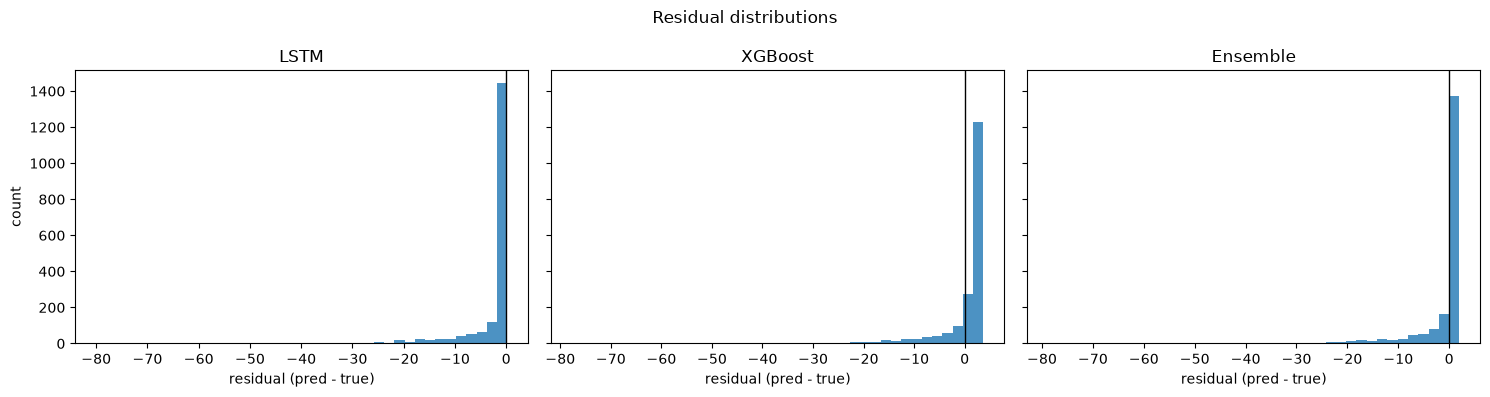

In [27]:
# ---------------------------------------------------------------------------
# Error Distribution / Residual Statistics (all models, side by side)
# ---------------------------------------------------------------------------
residual_rows = []
for evaluation in [lstm_eval, xgb_eval, ensemble_eval]:
    row = {'Model': evaluation['label']}
    row.update(evaluation['residual_stats'])
    residual_rows.append(row)

df_residuals = pd.DataFrame(residual_rows)
print(df_residuals.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, pred) in zip(
    axes,
    [('LSTM', lstm_pred_orig), ('XGBoost', xgb_pred_orig), ('Ensemble', ensemble_pred_orig)],
):
    resid = np.asarray(pred) - np.asarray(y_test_orig)
    ax.hist(resid, bins=40, alpha=0.8)
    ax.axvline(0, color='k', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel('residual (pred - true)')
axes[0].set_ylabel('count')
plt.suptitle('Residual distributions')
plt.tight_layout()
plt.show()


## Extended evaluation

Everything above this point is the reference pipeline's own evaluation, unchanged. What follows adds
four things it does not measure.

1. **The predictability ceiling.** How much better than a constant any forecast could possibly be,
   given the autocorrelation actually present in the series. This converts an RMSE figure into a
   share of the available margin.
2. **Event detection.** Contingency counts and the scores built on them - POD, FAR, CSI, frequency
   bias, HSS, ETS - plus ROC AUC. These measure whether the forecast *ranks* days correctly, which
   RMSE, MAE and R-squared cannot see because they score magnitude only.
3. **Skill scores** against explicit reference forecasts, including the naive and window-average
   forecasts defined in the baseline implementation.
4. **Accumulated seven-day totals**, further below.


In [28]:
# ---------------------------------------------------------------------------
# (a) The predictability ceiling.
#
# A forecast that carries no information can still score well on RMSE, because
# the best constant already achieves the target's own standard deviation. The
# question worth asking is how much better than that constant ANY forecast
# could be, given the autocorrelation actually present in the series. For a
# single lagged predictor the best achievable RMSE is sigma * sqrt(1 - r^2),
# so the whole margin available to a one-lag model is the gap between that and
# sigma. Every model's RMSE is then reported as a share of that margin.
# ---------------------------------------------------------------------------
lag1_test_orig = inv_boxcox1p(x_test_lag[:, -1], lam_value)
train_series_orig = rainfall.PRCP.to_numpy()[:DATA_CUTOFF]

sd_y = float(np.std(y_test_orig))
mean_y = float(np.mean(y_test_orig))
mean_train = float(np.mean(train_series_orig))

r_test = float(pearsonr(y_test_orig, lag1_test_orig)[0])
r_train = float(pd.Series(train_series_orig).autocorr(lag=1))

rmse_const_oracle = sd_y
rmse_const_trainmean = math.sqrt(sd_y ** 2 + (mean_train - mean_y) ** 2)
rmse_linear_test_r = sd_y * math.sqrt(1.0 - r_test ** 2)
rmse_linear_train_r = sd_y * math.sqrt(1.0 - r_train ** 2)
margin_in = rmse_const_oracle - rmse_linear_train_r

predictability_ceiling = {
    'target_sd': sd_y, 'target_mean': mean_y, 'train_mean': mean_train,
    'r_lag1_test': r_test, 'r_lag1_train': r_train,
    'rmse_constant_oracle': rmse_const_oracle,
    'rmse_constant_trainmean': rmse_const_trainmean,
    'rmse_linear_lag1_test_r': rmse_linear_test_r,
    'rmse_linear_lag1_train_r': rmse_linear_train_r,
    'margin_in': margin_in,
}

print("Lag-1 autocorrelation:")
print(f"  training portion            {r_train:+.4f}   (explains {100*r_train**2:.2f}% of variance)")
print(f"  scored test days            {r_test:+.4f}   (explains {100*r_test**2:.2f}% of variance)")
print()
rows = [
    ('Constant at the training mean', rmse_const_trainmean, ''),
    ('Constant at the test mean', rmse_const_oracle, 'ORACLE - uses test data'),
    ('Best linear lag-1 (test r)', rmse_linear_test_r, 'ORACLE - uses test data'),
    ('Best linear lag-1 (train r)', rmse_linear_train_r, 'achievable upper bound'),
]
print(pd.DataFrame(rows, columns=['Bound', 'RMSE', 'Note'])
      .to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print()
print(f"Total margin any one-lag model can win over the best constant: {margin_in:.4f} in")
print()

ceiling_rows = []
for label, pred in [('LSTM', lstm_pred_orig), ('XGBoost', xgb_pred_orig),
                    ('Ensemble', ensemble_pred_orig)]:
    rmse = math.sqrt(mean_squared_error(y_test_orig, pred))
    ceiling_rows.append({
        'Model': label,
        'RMSE': rmse,
        'vs best constant (in)': rmse_const_oracle - rmse,
        '% of margin captured': 100.0 * (rmse_const_oracle - rmse) / margin_in,
        'pred sd': float(np.std(pred)),
        'pred sd / target sd': float(np.std(pred)) / sd_y,
    })
df_ceiling = pd.DataFrame(ceiling_rows)
print(df_ceiling.to_string(index=False, float_format=lambda v: f'{v:.4f}'))


Lag-1 autocorrelation:
  training portion            +0.1154   (explains 1.33% of variance)
  scored test days            +0.0877   (explains 0.77% of variance)

                        Bound   RMSE                    Note
Constant at the training mean 5.5457                        
    Constant at the test mean 5.5397 ORACLE - uses test data
   Best linear lag-1 (test r) 5.5183 ORACLE - uses test data
  Best linear lag-1 (train r) 5.5027  achievable upper bound

Total margin any one-lag model can win over the best constant: 0.0370 in

   Model   RMSE  vs best constant (in)  % of margin captured  pred sd  pred sd / target sd
    LSTM 5.9031                -0.3634             -981.2578   0.0080               0.0014
 XGBoost 5.5291                 0.0106               28.6222   0.3453               0.0623
Ensemble 5.6172                -0.0775             -209.2036   0.1781               0.0322


In [29]:
# ---------------------------------------------------------------------------
# (b) Event detection.
#
# Two tables, and both are needed. The raw table applies the observation
# threshold directly to the forecast and answers "what happens if this is used
# as issued". The calibrated table first moves the forecast threshold to the
# point where the forecast event rate matches the observed rate on the
# VALIDATION slice, and answers the separate question "can this forecast rank
# days at all". Showing only the second would flatter the model; showing only
# the first would hide whatever ranking ability is there.
# ---------------------------------------------------------------------------
naive_test_orig = lag1_test_orig
avg_test_orig = inv_boxcox1p(
    scaler.inverse_transform(np.mean(x_test[:, :, 0], axis=1).reshape(-1, 1))[:, 0], lam_value)

EVENT_MODELS = OrderedDict([
    ('LSTM', lstm_pred_orig),
    ('XGBoost', xgb_pred_orig),
    ('Ensemble', ensemble_pred_orig),
    ('Persistence (naive)', naive_test_orig),
    ('Window average', avg_test_orig),
])

# Validation predictions of the FINAL models, used only to fit the calibration
# thresholds. The test set never chooses a threshold.
_val_xgb = inv_boxcox1p(xgb_model.predict(ens_score_xgb_x), lam_value)
_val_ens = w_lstm * lstm_score_pred + w_xgb * _val_xgb
VAL_FOR_CALIB = {'LSTM': lstm_score_pred, 'XGBoost': _val_xgb, 'Ensemble': _val_ens,
                 'Persistence (naive)': inv_boxcox1p(ens_score_xgb_x[:, -1], lam_value),
                 'Window average': inv_boxcox1p(
                     np.mean(ens_score_xgb_x, axis=1), lam_value)}


def event_table(calibrated):
    rows = []
    for t in EVENT_THRESHOLDS:
        for name, pred in EVENT_MODELS.items():
            pt = (calibrated_pred_threshold(ens_score_y_orig, VAL_FOR_CALIB[name], t)
                  if calibrated else None)
            m = event_detection_metrics(y_test_orig, pred, t, pt)
            rows.append({
                'Threshold': f'>{t:g} in', 'Model': name,
                'N events': m['a_hits'] + m['c_misses'],
                'Base rate': m['base_rate'], 'Pred rate': m['forecast_rate'],
                'Pred thr': m['pred_threshold'],
                'a': m['a_hits'], 'b': m['b_false_alarms'],
                'c': m['c_misses'], 'd': m['d_correct_neg'],
                'POD': m['POD'], 'FAR': m['FAR'], 'CSI': m['CSI'],
                'BIAS': m['BIAS'], 'HSS': m['HSS'], 'ETS': m['ETS'],
                'AUC': roc_auc(y_test_orig, pred, t),
                'AP': average_precision(y_test_orig, pred, t),
            })
    return pd.DataFrame(rows)


df_events_raw = event_table(calibrated=False)
df_events_cal = event_table(calibrated=True)

print("=== Raw: the observation threshold applied directly to the forecast ===")
print("Every model's output occupies a narrow band, so at the higher thresholds")
print("no forecast-yes event is issued at all. Those zeros and undefined values")
print("are the honest answer and are printed as they come out.")
print()
print(df_events_raw.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print()
print("=== Calibrated: forecast threshold set on the validation slice so the ===")
print("=== forecast event rate matches the observed rate. This isolates      ===")
print("=== whether the forecast can rank days, independent of its level.     ===")
print()
print(df_events_cal.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print()
print("AUC is unchanged between the two tables by construction: it depends only on")
print("the ordering of the forecast, which a threshold shift does not alter.")


=== Raw: the observation threshold applied directly to the forecast ===
Every model's output occupies a narrow band, so at the higher thresholds
no forecast-yes event is issued at all. Those zeros and undefined values
are the honest answer and are printed as they come out.

Threshold               Model  N events  Base rate  Pred rate  Pred thr   a    b   c    d    POD    FAR    CSI   BIAS    HSS    ETS    AUC     AP
    >0 in                LSTM       784     0.4215     1.0000    0.0000 784 1076   0    0 1.0000 0.5785 0.4215 2.3724 0.0000 0.0000 0.5665 0.4780
    >0 in             XGBoost       784     0.4215     1.0000    0.0000 784 1076   0    0 1.0000 0.5785 0.4215 2.3724 0.0000 0.0000 0.5539 0.4874
    >0 in            Ensemble       784     0.4215     1.0000    0.0000 784 1076   0    0 1.0000 0.5785 0.4215 2.3724 0.0000 0.0000 0.5557 0.4888
    >0 in Persistence (naive)       784     0.4215     0.4210    0.0000 410  373 374  703 0.5230 0.4764 0.3544 0.9987 0.1763 0.0967 0.6016 0.

In [30]:
# ---------------------------------------------------------------------------
# (c) Skill scores against reference forecasts, and MASE.
#
# The two simplest references are not invented here: naiveForecast and
# avgForecast are the reference forecasts defined in the baseline
# implementation (Data/Piers_1_2.ipynb), reproduced below unchanged and
# applied to this notebook's test windows.
# ---------------------------------------------------------------------------
def naiveForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = x_data[:,-1,0]
    return forecast

def avgForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = np.mean(x_data[:,:,0], axis=1)
    return forecast


def _to_orig(scaled_1d):
    return inv_boxcox1p(scaler.inverse_transform(np.asarray(scaled_1d).reshape(-1, 1))[:, 0],
                        lam_value)


ref_naive = _to_orig(naiveForecast(x_test))
ref_avg = _to_orig(avgForecast(x_test))

# Day-of-year climatology, fitted on the training portion only, smoothed with a
# centred fifteen-day window so a single wet anniversary does not dominate.
_train_df = rainfall.iloc[:DATA_CUTOFF]
_doy_mean = _train_df.groupby(_train_df.index.dayofyear).PRCP.mean()
_tripled = pd.concat([_doy_mean, _doy_mean, _doy_mean]).rolling(15, center=True).mean()
_doy_smooth = _tripled.iloc[len(_doy_mean):2 * len(_doy_mean)]
_doy_smooth.index = _doy_mean.index
_test_dates = rainfall.index[DATA_CUTOFF + WINDOW_SIZE:TOTAL_DATA_LENGTH]
ref_climatology = np.array([float(_doy_smooth.get(d.dayofyear, mean_train))
                            for d in _test_dates])
ref_train_const = np.full_like(y_test_orig, mean_train)
ref_oracle_const = np.full_like(y_test_orig, mean_y)

REFERENCES = OrderedDict([
    ('Persistence (naive)', ref_naive),
    ('Window average', ref_avg),
    ('Climatology (train only)', ref_climatology),
    ('Constant = train mean', ref_train_const),
])
ORACLE_REFERENCES = OrderedDict([('Constant = test mean [ORACLE]', ref_oracle_const)])

print("Reference forecasts, scored in their own right:")
_ref_rows = []
for nm, r in list(REFERENCES.items()) + list(ORACLE_REFERENCES.items()):
    _ref_rows.append({'Reference': nm,
                      'RMSE': math.sqrt(mean_squared_error(y_test_orig, r)),
                      'MAE': mean_absolute_error(y_test_orig, r),
                      'pred sd': float(np.std(r))})
print(pd.DataFrame(_ref_rows).to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print()

skill_rows = []
for name, pred in [('LSTM', lstm_pred_orig), ('XGBoost', xgb_pred_orig),
                   ('Ensemble', ensemble_pred_orig)]:
    row = {'Model': name}
    for rn, r in REFERENCES.items():
        row[f'MSE skill vs {rn}'] = skill_score(y_test_orig, pred, r, 'mse')
    for rn, r in ORACLE_REFERENCES.items():
        row[f'MSE skill vs {rn}'] = skill_score(y_test_orig, pred, r, 'mse')
    row['MAE skill vs Persistence'] = skill_score(y_test_orig, pred, ref_naive, 'mae')
    row['MASE (train denom)'] = mase(y_test_orig, pred, train_series_orig)
    row['MASE (test denom)'] = mase(y_test_orig, pred, y_test_orig)
    skill_rows.append(row)

df_skill = pd.DataFrame(skill_rows)
print("Skill scores. Zero means no better than the reference; negative means worse.")
print(df_skill.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print()
print("Two readings worth stating explicitly.")
print("  R-squared IS the MSE skill score against the constant at the test mean, which")
print("  is why an R-squared near zero and 'no better than a constant' are one statement.")
print("  MASE below 1 is easy to reach on a spiky daily series, because the denominator")
print("  is the mean day-to-day jump. Here it mostly measures smoothness, not skill.")


Reference forecasts, scored in their own right:
                    Reference   RMSE    MAE  pred sd
          Persistence (naive) 7.4828 3.4744   5.5399
               Window average 5.8772 2.3057   0.0924
     Climatology (train only) 5.5532 3.0650   0.5423
        Constant = train mean 5.5457 3.0604   0.0000
Constant = test mean [ORACLE] 5.5397 3.2099   0.0000

Skill scores. Zero means no better than the reference; negative means worse.
   Model  MSE skill vs Persistence (naive)  MSE skill vs Window average  MSE skill vs Climatology (train only)  MSE skill vs Constant = train mean  MSE skill vs Constant = test mean [ORACLE]  MAE skill vs Persistence  MASE (train denom)  MASE (test denom)
    LSTM                            0.3777                      -0.0088                                -0.1300                             -0.1330                                     -0.1355                    0.3393              0.7445             0.6603
 XGBoost                            0.4540  

Component spread on the test set: LSTM sd 0.0080 in, XGBoost sd 0.3453 in, observed sd 5.5397 in



Selected points along the weighting frontier:
 w_lstm   RMSE    MAE      R2   mean  AUC>0.5  AUC>5
 0.0000 5.5291 3.1996  0.0038 2.2833   0.5555 0.5767
 0.2000 5.5432 2.9687 -0.0013 1.8711   0.5559 0.5765
 0.4800 5.6155 2.6753 -0.0275 1.2940   0.5567 0.5763
 0.5000 5.6229 2.6562 -0.0303 1.2528   0.5568 0.5762
 1.0000 5.9031 2.2954 -0.1355 0.2223   0.5425 0.4882

AUC>0.5 across every weight below 1.0 spans 0.5555 to 0.5701, a range of 0.0146.

Why that range is essentially zero: with one component's spread three orders of
magnitude below the target's, any blend with w_lstm < 1 is an increasing affine
function of the other component, and every rank-based score is invariant under
an increasing transform. The weighting step therefore decides only WHERE the
forecast level sits, not how well it discriminates. RMSE pulls that level toward
the mean (2.261 in) and MAE pulls it toward the median (0.000 in), which is the whole of the trade-off below.

A further note on the rule itself. Inverse-RM

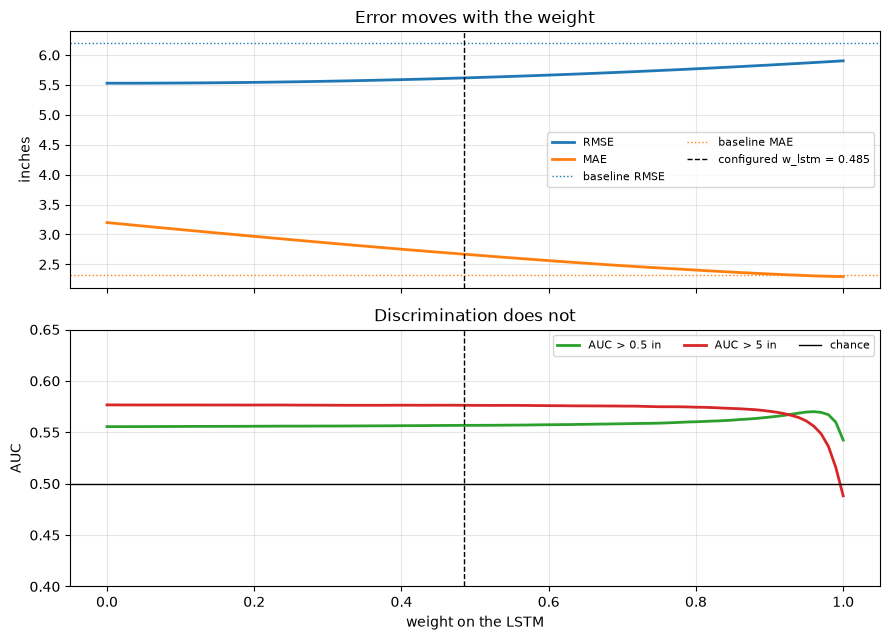

In [31]:
# ---------------------------------------------------------------------------
# The ensemble weighting step, examined but not altered.
#
# The configured rule is left exactly as the reference pipeline defines it.
# What follows is analysis: it establishes what the weight can and cannot do,
# so the ensemble result is reported with the right claim attached to it.
# ---------------------------------------------------------------------------
lstm_sd = float(np.std(lstm_pred_orig))
xgb_sd = float(np.std(xgb_pred_orig))
print(f"Component spread on the test set: LSTM sd {lstm_sd:.4f} in, "
      f"XGBoost sd {xgb_sd:.4f} in, observed sd {sd_y:.4f} in")
print()

ws = np.linspace(0.0, 1.0, 101)
rows = []
for w in ws:
    p = w * lstm_pred_orig + (1.0 - w) * xgb_pred_orig
    rows.append({'w_lstm': w,
                 'RMSE': math.sqrt(mean_squared_error(y_test_orig, p)),
                 'MAE': mean_absolute_error(y_test_orig, p),
                 'R2': r2_score(y_test_orig, p),
                 'mean': float(np.mean(p)),
                 'AUC>0.5': roc_auc(y_test_orig, p, 0.5),
                 'AUC>5': roc_auc(y_test_orig, p, 5.0)})
df_frontier = pd.DataFrame(rows)

_marks = df_frontier[df_frontier['w_lstm'].isin([0.0, 0.2, 0.5, round(w_lstm, 2), 1.0])]
print("Selected points along the weighting frontier:")
print(_marks.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print()
_auc_span = df_frontier.loc[df_frontier['w_lstm'] < 1.0, 'AUC>0.5']
print(f"AUC>0.5 across every weight below 1.0 spans {_auc_span.min():.4f} to "
      f"{_auc_span.max():.4f}, a range of {_auc_span.max()-_auc_span.min():.4f}.")
print()
print("Why that range is essentially zero: with one component's spread three orders of")
print("magnitude below the target's, any blend with w_lstm < 1 is an increasing affine")
print("function of the other component, and every rank-based score is invariant under")
print("an increasing transform. The weighting step therefore decides only WHERE the")
print("forecast level sits, not how well it discriminates. RMSE pulls that level toward")
print(f"the mean ({mean_y:.3f} in) and MAE pulls it toward the median "
      f"({float(np.median(y_test_orig)):.3f} in), which is the whole of the trade-off below.")
print()
print("A further note on the rule itself. Inverse-RMSE weighting is derived for combining")
print("approximately unbiased estimators whose errors are not strongly correlated. Here one")
print(f"component carries a bias of {lstm_eval['bias']:.3f} in, and because both are")
print("near-constant their error series are almost perfectly correlated. Both premises")
print("fail, which is why the derived weight lands where it does. That is an observation")
print("about the rule; the rule itself is left unchanged.")

fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)

ax = axes[0]
ax.plot(df_frontier['w_lstm'], df_frontier['RMSE'], label='RMSE', color='tab:blue', lw=2)
ax.plot(df_frontier['w_lstm'], df_frontier['MAE'], label='MAE', color='tab:orange', lw=2)
ax.axhline(BASELINE_RMSE, color='tab:blue', ls=':', lw=1, label='baseline RMSE')
ax.axhline(BASELINE_MAE, color='tab:orange', ls=':', lw=1, label='baseline MAE')
ax.axvline(w_lstm, color='k', ls='--', lw=1, label=f'configured w_lstm = {w_lstm:.3f}')
ax.set_ylabel('inches')
ax.set_title('Error moves with the weight')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(df_frontier['w_lstm'], df_frontier['AUC>0.5'], color='tab:green', lw=2,
        label='AUC > 0.5 in')
ax.plot(df_frontier['w_lstm'], df_frontier['AUC>5'], color='tab:red', lw=2,
        label='AUC > 5 in')
ax.axhline(0.5, color='k', lw=1, label='chance')
ax.axvline(w_lstm, color='k', ls='--', lw=1)
ax.set_ylim(0.40, 0.65)
ax.set_xlabel('weight on the LSTM')
ax.set_ylabel('AUC')
ax.set_title('Discrimination does not')
ax.legend(fontsize=8, ncol=3)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(MODEL_DIR / 'figures' / 'ensemble_frontier.png', dpi=150)
plt.show()

df_frontier.to_csv(MODEL_DIR / 'sweeps' / 'e_ensemble_frontier.csv', index=False)


Change ledger. The reference AUC values are the measured figures for the
v2_static predictions; every other reference value is read from its metadata.

              Metric  v2_static  This run   Delta Better?
  Ensemble RMSE (in)     5.6419    5.6172 -0.0247     yes
   Ensemble MAE (in)     2.6107    2.6708  0.0601      no
   Ensemble MAPE (%)   101.5141  109.8105  8.2964      no
         Ensemble R2    -0.0372   -0.0282  0.0091     yes
  Ensemble bias (in)    -1.1073   -0.9770  0.1303     yes
   XGBoost RMSE (in)     5.5320    5.5291 -0.0029     yes
    XGBoost MAE (in)     3.1341    3.1996  0.0655      no
XGBoost pred sd (in)     5.5312    0.3453 -5.1859        
  XGBoost AUC > 0 in     0.5466    0.5539  0.0073     yes
XGBoost AUC > 0.5 in     0.5463    0.5555  0.0092     yes
  XGBoost AUC > 2 in     0.5539    0.5732  0.0193     yes
  XGBoost AUC > 5 in     0.5643    0.5767  0.0124     yes


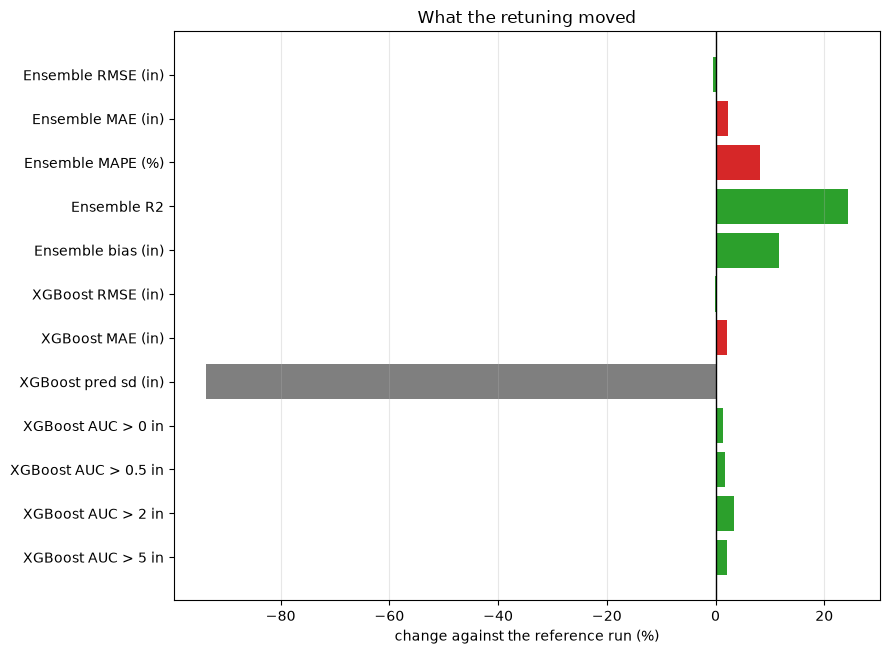

In [32]:
# ---------------------------------------------------------------------------
# The change ledger. The diff table above is the input side of the retuning;
# this is the output side. Every row is this run against the reference run.
# ---------------------------------------------------------------------------
_ref_ens = REFERENCE_EVAL['ensemble']
_ref_xgb = REFERENCE_EVAL['xgboost']

REFERENCE_AUC = {0.0: 0.5466, 0.5: 0.5463, 2.0: 0.5539, 5.0: 0.5643}

ledger = [
    ('Ensemble RMSE (in)', _ref_ens['rmse'], ensemble_eval['rmse'], 'lower'),
    ('Ensemble MAE (in)', _ref_ens['mae'], ensemble_eval['mae'], 'lower'),
    ('Ensemble MAPE (%)', _ref_ens['mape'], ensemble_eval['mape'], 'lower'),
    ('Ensemble R2', _ref_ens['r2'], ensemble_eval['r2'], 'higher'),
    ('Ensemble bias (in)', _ref_ens['bias'], ensemble_eval['bias'], 'toward zero'),
    ('XGBoost RMSE (in)', _ref_xgb['rmse'], xgb_eval['rmse'], 'lower'),
    ('XGBoost MAE (in)', _ref_xgb['mae'], xgb_eval['mae'], 'lower'),
    ('XGBoost pred sd (in)', float(_ref_xgb['residual_stats']['std']), float(np.std(xgb_pred_orig)),
     'n/a'),
]
for t in EVENT_THRESHOLDS:
    ledger.append((f'XGBoost AUC > {t:g} in', REFERENCE_AUC[t],
                   roc_auc(y_test_orig, xgb_pred_orig, t), 'higher'))

rows = []
for name, ref, new, direction in ledger:
    d = new - ref
    if direction == 'lower':
        better = 'yes' if d < 0 else ('no' if d > 0 else 'same')
    elif direction == 'higher':
        better = 'yes' if d > 0 else ('no' if d < 0 else 'same')
    elif direction == 'toward zero':
        better = 'yes' if abs(new) < abs(ref) else ('no' if abs(new) > abs(ref) else 'same')
    else:
        better = ''
    rows.append({'Metric': name, 'v2_static': ref, 'This run': new, 'Delta': d,
                 'Better?': better})

df_ledger = pd.DataFrame(rows)
print("Change ledger. The reference AUC values are the measured figures for the")
print("v2_static predictions; every other reference value is read from its metadata.\n")
print(df_ledger.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

_plot = df_ledger[df_ledger['v2_static'].abs() > 1e-9].copy()
_plot['pct'] = 100.0 * _plot['Delta'] / _plot['v2_static'].abs()
fig, ax = plt.subplots(figsize=(9, 0.42 * len(_plot) + 1.6))
_colors = ['tab:green' if b == 'yes' else ('tab:red' if b == 'no' else 'tab:gray')
           for b in _plot['Better?']]
ax.barh(_plot['Metric'], _plot['pct'], color=_colors)
ax.axvline(0, color='k', lw=1)
ax.set_xlabel('change against the reference run (%)')
ax.set_title('What the retuning moved')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_DIR / 'figures' / 'change_ledger.png', dpi=150)
plt.show()


In [33]:
# ---------------------------------------------------------------------------
# Computational cost vs. benefit trade-off (objective 1.3.1.1.5). XGBoost's
# training cost is negligible, so LSTM's training time is treated as the
# "additional" cost of including it in the pipeline. Benefit is measured as
# the ensemble's improvement over XGBoost alone, not over the baseline --
# XGBoost alone is the cheap alternative LSTM's added cost is actually being
# weighed against, since it is already the cheaper of the two component
# models on its own.
# ---------------------------------------------------------------------------
cost_ratio = lstm_train_seconds / xgb_train_seconds

rmse_benefit_vs_xgb = xgb_eval['rmse'] - ensemble_eval['rmse']
mae_benefit_vs_xgb = xgb_eval['mae'] - ensemble_eval['mae']

def intensity_mae(table, label):
    return float(table.loc[table['Intensity'] == label, 'MAE'].iloc[0])

dry_benefit = intensity_mae(xgb_intensity, 'No Rain (0 in)') - intensity_mae(ensemble_intensity, 'No Rain (0 in)')
moderate_benefit = intensity_mae(xgb_intensity, 'Moderate (0.2-0.5 in)') - intensity_mae(ensemble_intensity, 'Moderate (0.2-0.5 in)')
heavy_benefit = intensity_mae(xgb_intensity, 'Heavy (>0.5 in)') - intensity_mae(ensemble_intensity, 'Heavy (>0.5 in)')

print(f"LSTM training cost: {lstm_train_seconds:.1f}s vs XGBoost: {xgb_train_seconds:.3f}s ({cost_ratio:,.0f}x)")
print()
print("Benefit of the ensemble over XGBoost alone (positive = ensemble better, negative = worse):")
print(f"  RMSE (overall):     {rmse_benefit_vs_xgb:+.4f} in")
print(f"  MAE (overall):      {mae_benefit_vs_xgb:+.4f} in")
print(f"  MAE, No Rain days:  {dry_benefit:+.4f} in")
print(f"  MAE, Moderate days: {moderate_benefit:+.4f} in")
print(f"  MAE, Heavy days:    {heavy_benefit:+.4f} in")

cost_benefit = {
    'lstm_train_seconds': lstm_train_seconds,
    'xgboost_train_seconds': xgb_train_seconds,
    'cost_ratio_lstm_over_xgboost': cost_ratio,
    'ensemble_vs_xgboost_alone': {
        'rmse_benefit': rmse_benefit_vs_xgb,
        'mae_benefit_overall': mae_benefit_vs_xgb,
        'mae_benefit_no_rain': dry_benefit,
        'mae_benefit_moderate': moderate_benefit,
        'mae_benefit_heavy': heavy_benefit,
    },
}
if dry_benefit > 0:
    cost_benefit['seconds_per_inch_no_rain_mae_gained'] = lstm_train_seconds / dry_benefit
    print()
    print(f"LSTM training seconds spent per inch of No-Rain-day MAE gained: {cost_benefit['seconds_per_inch_no_rain_mae_gained']:,.0f}")
if moderate_benefit > 0:
    cost_benefit['seconds_per_inch_moderate_mae_gained'] = lstm_train_seconds / moderate_benefit
    print(f"LSTM training seconds spent per inch of Moderate-day MAE gained: {cost_benefit['seconds_per_inch_moderate_mae_gained']:,.0f}")


LSTM training cost: 724.2s vs XGBoost: 0.869s (833x)

Benefit of the ensemble over XGBoost alone (positive = ensemble better, negative = worse):
  RMSE (overall):     -0.0881 in
  MAE (overall):      +0.5288 in
  MAE, No Rain days:  +0.9832 in
  MAE, Moderate days: +1.0152 in
  MAE, Heavy days:    -0.4353 in

LSTM training seconds spent per inch of No-Rain-day MAE gained: 737
LSTM training seconds spent per inch of Moderate-day MAE gained: 713


## Accumulated seven-day totals

The one-day forecast is rolled forward recursively to a seven-day horizon and the seven daily values
are summed, giving an accumulated weekly total. A weekly total is smoother and far less zero-inflated
than a daily value, so it is a plausibly better-posed target for the same models.

**Verdict rule, fixed before any number below is produced.** Accumulation is reported as helping only
if **all three** of the following hold:

- accumulated R-squared > 0.05
- MSE skill score against the seven-times-training-mean constant > 0.05
- AUC at the weekly median threshold > 0.60

If any one fails, the reported finding is that accumulation does not recover skill.

**Three cautions that govern how the tables below are read.**

A seven-day sum has a larger mean and a smaller coefficient of variation than a daily value, so its
absolute RMSE rises while its relative error falls, with no change in skill whatsoever. RMSE and MAE
are therefore reported but are **not** comparable to the daily table, and are not the headline. The
headline is the skill scores, which are computed against references at the same aggregation and are
immune to that effect.

The predicted and observed standard deviations are printed in every table. A near-constant daily
forecast produces a near-constant weekly forecast, and that column is where it shows.

Anchors overlap by six of their seven days, so the accumulated samples are not independent. The
effective sample size is roughly one seventh of the nominal count, and a strided, non-overlapping
variant is reported alongside as a robustness check.


In [34]:
# ---------------------------------------------------------------------------
# Recursive seven-day rollout, then accumulation.
#
# Each day's own prediction is fed back into the lookback window in place of
# the true value, out to seven days; the seven daily values are then summed.
# Nothing is retrained here. The reference run's saved models are put through
# the identical rollout so the two can be compared at the weekly scale.
# ---------------------------------------------------------------------------
HORIZON = 7


def make_anchor_windows(series, window, horizon):
    n = len(series) - window - horizon + 1
    w = np.array([series[i:i + window] for i in range(n)])
    f = np.array([series[i + window:i + window + horizon] for i in range(n)])
    return w, f


lstm_windows, _ = make_anchor_windows(lstm_test_series, WINDOW_SIZE, HORIZON)
xgb_windows, xgb_futures = make_anchor_windows(xgb_test_series, WINDOW_SIZE, HORIZON)
true_future_orig = inv_boxcox1p(xgb_futures, lam_value)
n_anchors = len(xgb_windows)
last_known_orig = inv_boxcox1p(xgb_windows[:, -1], lam_value)
persistence_by_h = np.tile(last_known_orig.reshape(-1, 1), (1, HORIZON))


def recursive_rollout(lstm_net, xgb_reg, wl, wx):
    lw = lstm_windows.copy()
    xw = xgb_windows.copy()
    lstm_by_h, xgb_by_h = [], []
    for _ in range(HORIZON):
        lp = lstm_net.predict(lw.reshape(-1, WINDOW_SIZE, 1), verbose=0).flatten()
        xp = xgb_reg.predict(xw)
        lstm_by_h.append(inv_boxcox1p(
            scaler.inverse_transform(lp.reshape(-1, 1))[:, 0], lam_value))
        xgb_by_h.append(inv_boxcox1p(xp, lam_value))
        lw = np.hstack([lw[:, 1:], lp.reshape(-1, 1)])
        xw = np.hstack([xw[:, 1:], xp.reshape(-1, 1)])
    L = np.column_stack(lstm_by_h)
    X = np.column_stack(xgb_by_h)
    return L, X, wl * L + wx * X


t0 = time.time()
lstm_by_h, xgb_by_h, ens_by_h = recursive_rollout(model, xgb_model, w_lstm, w_xgb)
print(f"Rollout for {n_anchors} anchors x {HORIZON} lead days complete in {time.time()-t0:.1f}s")

_ref_lstm = tf.keras.models.load_model(STATIC_DIR / "lstm_model.keras")
_ref_xgb = xgb.XGBRegressor()
_ref_xgb.load_model(str(STATIC_DIR / "xgboost_model.json"))
_rw = REFERENCE_RUN['ensemble']
_, _, ref_ens_by_h = recursive_rollout(_ref_lstm, _ref_xgb,
                                       _rw['weight_lstm'], _rw['weight_xgb'])
print("Reference-run rollout complete.")
print()

acc_true = true_future_orig.sum(axis=1)
ACCUM = OrderedDict([
    ('LSTM', lstm_by_h.sum(axis=1)),
    ('XGBoost', xgb_by_h.sum(axis=1)),
    ('Ensemble', ens_by_h.sum(axis=1)),
    ('Ensemble (v2_static)', ref_ens_by_h.sum(axis=1)),
    ('Persistence x7', persistence_by_h.sum(axis=1)),
])
acc_train_const = np.full_like(acc_true, mean_train * HORIZON)
acc_clim = np.full_like(acc_true, float(np.mean(ref_climatology)) * HORIZON)

eff_n = int(round(n_anchors / HORIZON))
print(f"Nominal accumulated samples: {n_anchors}. Anchors overlap by six of seven days,")
print(f"so the effective independent sample size is about {eff_n} weeks. Any statement")
print("about precision below should use that figure, not the nominal one.")
print()

med_thr = float(np.median(acc_true))
rows = []
for name, p in ACCUM.items():
    rows.append({
        'Model': name,
        'RMSE': math.sqrt(mean_squared_error(acc_true, p)),
        'MAE': mean_absolute_error(acc_true, p),
        'R2': r2_score(acc_true, p),
        'pred sd': float(np.std(p)),
        'pred sd / true sd': float(np.std(p)) / float(np.std(acc_true)),
        'skill vs 7x train mean': skill_score(acc_true, p, acc_train_const, 'mse'),
        'skill vs climatology x7': skill_score(acc_true, p, acc_clim, 'mse'),
        'skill vs persistence x7': skill_score(acc_true, p, ACCUM['Persistence x7'], 'mse'),
        f'AUC > median ({med_thr:.1f} in)': roc_auc(acc_true, p, med_thr),
    })
df_accum = pd.DataFrame(rows)
print(f"Accumulated seven-day totals. Observed mean {acc_true.mean():.2f} in, "
      f"sd {acc_true.std():.2f} in.")
print("RMSE and MAE are shown for completeness but are NOT comparable to the daily")
print("table: a weekly sum has a larger mean, so its absolute error is larger at equal")
print("skill. The skill columns are the ones that carry the argument.\n")
print(df_accum.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print()

_s = slice(None, None, HORIZON)
rows = []
for name, p in ACCUM.items():
    rows.append({'Model': name,
                 'R2 (non-overlapping)': r2_score(acc_true[_s], p[_s]),
                 'skill vs 7x train mean': skill_score(acc_true[_s], p[_s],
                                                       acc_train_const[_s], 'mse'),
                 f'AUC > median': roc_auc(acc_true[_s], p[_s], med_thr)})
print(f"Robustness: the same table on {len(acc_true[_s])} non-overlapping weeks.")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print()

WEEKLY_THRESHOLDS = (1.0, 5.0, 10.0, 20.0)
rows = []
for t in WEEKLY_THRESHOLDS:
    for name, p in ACCUM.items():
        m = event_detection_metrics(acc_true, p, t,
                                    float(np.quantile(p, 1.0 - np.mean(acc_true > t))))
        rows.append({'Threshold': f'>{t:g} in', 'Model': name,
                     'Base rate': m['base_rate'], 'POD': m['POD'], 'FAR': m['FAR'],
                     'CSI': m['CSI'], 'HSS': m['HSS'],
                     'AUC': roc_auc(acc_true, p, t)})
df_accum_events = pd.DataFrame(rows)
print("Weekly event detection, thresholds calibrated to the observed rate.")
print(df_accum_events.to_string(index=False, float_format=lambda v: f'{v:.4f}'))


Rollout for 1854 anchors x 7 lead days complete in 5.1s


Reference-run rollout complete.

Nominal accumulated samples: 1854. Anchors overlap by six of seven days,
so the effective independent sample size is about 265 weeks. Any statement
about precision below should use that figure, not the nominal one.

Accumulated seven-day totals. Observed mean 15.87 in, sd 15.53 in.
RMSE and MAE are shown for completeness but are NOT comparable to the daily
table: a weekly sum has a larger mean, so its absolute error is larger at equal
skill. The skill columns are the ones that carry the argument.

               Model    RMSE     MAE      R2  pred sd  pred sd / true sd  skill vs 7x train mean  skill vs climatology x7  skill vs persistence x7  AUC > median (11.7 in)
                LSTM 21.1268 14.5969 -0.8504   0.0397             0.0026                 -0.8245                  -0.8219                   0.7416                  0.4760
             XGBoost 15.5193 11.5443  0.0015   0.6574             0.0423                  0.0155                   0.0169 

In [35]:
# ---------------------------------------------------------------------------
# Verdict on accumulation, evaluated against the rule fixed before the numbers
# existed. Both outcomes are written out here, so whichever one the run
# produces, the wording was settled in advance.
# ---------------------------------------------------------------------------
_e = df_accum[df_accum['Model'] == 'Ensemble'].iloc[0]
acc_r2 = float(_e['R2'])
acc_skill = float(_e['skill vs 7x train mean'])
acc_auc = float(_e[f'AUC > median ({med_thr:.1f} in)'])

CRITERIA = OrderedDict([
    ('accumulated R2 > 0.05', (acc_r2, 0.05, acc_r2 > 0.05)),
    ('MSE skill vs 7x train mean > 0.05', (acc_skill, 0.05, acc_skill > 0.05)),
    ('AUC at the weekly median > 0.60', (acc_auc, 0.60, acc_auc > 0.60)),
])
ACCUM_SUPPORTED = all(v[2] for v in CRITERIA.values())

print("Pre-registered criteria, evaluated:")
for name, (val, thr, ok) in CRITERIA.items():
    print(f"  [{'PASS' if ok else 'FAIL'}]  {name:38s} observed {val:+.4f}")
print()

daily_r2 = float(ensemble_eval['r2'])
_ratio = float(_e['pred sd / true sd'])

if ACCUM_SUPPORTED:
    print(
        "VERDICT: SUPPORTED.\n\n"
        f"Accumulating to a seven-day total lifts R-squared from {daily_r2:+.4f} at the daily\n"
        f"scale to {acc_r2:+.4f}, with an MSE skill score of {acc_skill:+.4f} against a constant\n"
        f"at seven times the training mean and an AUC of {acc_auc:.4f} at the weekly median.\n"
        "All three pre-registered criteria are met, so the weekly total is the better-posed\n"
        "target for these models and is the aggregation at which the product is usable.")
else:
    _failed = [n for n, v in CRITERIA.items() if not v[2]]
    print(
        "VERDICT: NOT SUPPORTED.\n\n"
        f"Accumulation does not recover skill. R-squared moves from {daily_r2:+.4f} at the daily\n"
        f"scale to {acc_r2:+.4f} on weekly totals, the MSE skill score against a constant at seven\n"
        f"times the training mean is {acc_skill:+.4f}, and AUC at the weekly median is {acc_auc:.4f}.\n"
        f"Criteria not met: {', '.join(_failed)}.\n\n"
        f"The mechanism is visible in the spread column: the accumulated forecast has a standard\n"
        f"deviation {_ratio:.1%} of the observed one, because summing seven near-constant daily\n"
        "values produces a near-constant weekly value. Aggregation changes the scale of the\n"
        "target, not the amount of information available about it. Reported as measured.")


Pre-registered criteria, evaluated:
  [FAIL]  accumulated R2 > 0.05                  observed -0.2019
  [FAIL]  MSE skill vs 7x train mean > 0.05      observed -0.1850
  [FAIL]  AUC at the weekly median > 0.60        observed +0.5243

VERDICT: NOT SUPPORTED.

Accumulation does not recover skill. R-squared moves from -0.0282 at the daily
scale to -0.2019 on weekly totals, the MSE skill score against a constant at seven
times the training mean is -0.1850, and AUC at the weekly median is 0.5243.
Criteria not met: accumulated R2 > 0.05, MSE skill vs 7x train mean > 0.05, AUC at the weekly median > 0.60.

The mechanism is visible in the spread column: the accumulated forecast has a standard
deviation 2.2% of the observed one, because summing seven near-constant daily
values produces a near-constant weekly value. Aggregation changes the scale of the
target, not the amount of information available about it. Reported as measured.


In [36]:
# ---------------------------------------------------------------------------
# Save trained model artifacts so a separate inference-only application (the
# Streamlit website) can load them and run predictions without retraining.
# ---------------------------------------------------------------------------
lstm_model_path = MODEL_DIR / "lstm_model.keras"
xgb_model_path = MODEL_DIR / "xgboost_model.json"
scaler_path = MODEL_DIR / "scaler.joblib"

model.save(lstm_model_path)
xgb_model.save_model(str(xgb_model_path))
joblib.dump(scaler, scaler_path)

print(f"Saved LSTM model to {lstm_model_path} ({lstm_model_path.stat().st_size / 1024:.1f} KB)")
print(f"Saved XGBoost model to {xgb_model_path} ({xgb_model_path.stat().st_size / 1024:.1f} KB)")
print(f"Saved scaler to {scaler_path} ({scaler_path.stat().st_size / 1024:.1f} KB)")

# ---------------------------------------------------------------------------
# Verify the saved artifacts are actually usable for inference: reload each
# one fresh (not the in-memory objects) and confirm predictions on the test
# set match the in-memory model's predictions closely. This is the check
# that proves the saved files work, not just that save() didn't raise.
# ---------------------------------------------------------------------------
loaded_lstm = tf.keras.models.load_model(lstm_model_path)
loaded_xgb = xgb.XGBRegressor()
loaded_xgb.load_model(str(xgb_model_path))
loaded_scaler = joblib.load(scaler_path)

reload_lstm_pred_scaled = loaded_lstm.predict(x_test, verbose=0)
reload_lstm_pred_bc = loaded_scaler.inverse_transform(reload_lstm_pred_scaled)[:, 0]
reload_lstm_pred_orig = inv_boxcox1p(reload_lstm_pred_bc, lam_value)

reload_xgb_pred_bc = loaded_xgb.predict(x_test_lag)
reload_xgb_pred_orig = inv_boxcox1p(reload_xgb_pred_bc, lam_value)

lstm_reload_max_abs_diff = float(np.max(np.abs(reload_lstm_pred_orig - lstm_pred_orig)))
xgb_reload_max_abs_diff = float(np.max(np.abs(reload_xgb_pred_orig - xgb_pred_orig)))

print()
print(f"LSTM reload max abs difference vs in-memory model: {lstm_reload_max_abs_diff:.8f} in")
print(f"XGBoost reload max abs difference vs in-memory model: {xgb_reload_max_abs_diff:.8f} in")

RELOAD_TOLERANCE = 1e-4
lstm_reload_ok = lstm_reload_max_abs_diff < RELOAD_TOLERANCE
xgb_reload_ok = xgb_reload_max_abs_diff < RELOAD_TOLERANCE
print(f"LSTM reload check: {'PASS' if lstm_reload_ok else 'FAIL'}")
print(f"XGBoost reload check: {'PASS' if xgb_reload_ok else 'FAIL'}")
if not (lstm_reload_ok and xgb_reload_ok):
    raise RuntimeError("Saved model artifacts do not reproduce in-memory predictions within tolerance.")

artifact_verification = {
    'lstm_model_path': str(lstm_model_path),
    'xgboost_model_path': str(xgb_model_path),
    'scaler_path': str(scaler_path),
    'lstm_reload_max_abs_diff': lstm_reload_max_abs_diff,
    'xgboost_reload_max_abs_diff': xgb_reload_max_abs_diff,
    'reload_tolerance': RELOAD_TOLERANCE,
    'lstm_reload_passed': lstm_reload_ok,
    'xgboost_reload_passed': xgb_reload_ok,
}


Saved LSTM model to models\v2_retuned\lstm_model.keras (140.8 KB)
Saved XGBoost model to models\v2_retuned\xgboost_model.json (107.3 KB)
Saved scaler to models\v2_retuned\scaler.joblib (0.7 KB)



LSTM reload max abs difference vs in-memory model: 0.00000000 in
XGBoost reload max abs difference vs in-memory model: 0.00000000 in
LSTM reload check: PASS
XGBoost reload check: PASS


In [37]:
# ---------------------------------------------------------------------------
# Save results. The schema of the reference run is kept exactly, so any
# consumer that reads the reference metadata reads this too; the retuning
# record is added alongside as extra keys.
# ---------------------------------------------------------------------------
def _jsonable(obj):
    if isinstance(obj, dict):
        return {k: _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    return obj


results = {
    'model_type': 'LSTM_XGBoost_Ensemble_static',
    'lstm_config': {
        'window_size': WINDOW_SIZE,
        'units_layer1': LSTM_UNITS_LAYER1,
        'units_layer2': LSTM_UNITS_LAYER2,
        'dense_units': LSTM_DENSE_UNITS,
        'dropout': LSTM_DROPOUT,
        'epochs': LSTM_EPOCHS,
        'batch_size': LSTM_BATCH_SIZE,
        'learning_rate': LSTM_LEARNING_RATE,
        'momentum': LSTM_MOMENTUM,
    },
    'xgboost_config': dict(XGB_STATIC_PARAMS, huber_slope=XGB_HUBER_SLOPE, lag_window=WINDOW_SIZE,
                           n_estimators_used=n_estimators_used, objective=CONFIG['XGB_OBJECTIVE'],
                           sample_weight_power=CONFIG['XGB_SAMPLE_WEIGHT_POWER']),
    'preprocessing': {'box_cox_lambda': float(lam_value), 'scaler_type': 'MinMaxScaler'},
    'ensemble': {'strategy': 'Inverse RMSE weighting', 'weight_lstm': float(w_lstm), 'weight_xgb': float(w_xgb)},
    'baseline_reference': {'rmse': BASELINE_RMSE, 'mae': BASELINE_MAE, 'mape': BASELINE_MAPE},
    'evaluation': {
        'lstm': {k: v for k, v in lstm_eval.items() if k != 'label'},
        'xgboost': {k: v for k, v in xgb_eval.items() if k != 'label'},
        'ensemble': {k: v for k, v in ensemble_eval.items() if k != 'label'},
    },
    'rainfall_intensity_performance': {
        'lstm': lstm_intensity.to_dict(orient='records'),
        'xgboost': xgb_intensity.to_dict(orient='records'),
        'ensemble': ensemble_intensity.to_dict(orient='records'),
    },
    'artifacts': artifact_verification,
    'cost_benefit_tradeoff': cost_benefit,
    'computational_cost': {
        'lstm_train_seconds': lstm_train_seconds,
        'lstm_predict_seconds': lstm_predict_seconds,
        'xgboost_train_seconds': xgb_train_seconds,
        'xgboost_predict_seconds': xgb_predict_seconds,
    },
    # ---- added by this notebook ----
    'retuning': {
        'derived_from': 'runs/static/LSTM_XGBoost_Ensemble_Precipitation_STATIC.ipynb',
        'helper_cell_sha256': HELPER_CELL_SHA256,
        'baseline_config': dict(BASELINE_CONFIG),
        'config': dict(CONFIG),
        'frozen_keys': sorted(FROZEN_KEYS),
        'changed_keys': sorted(k for k in BASELINE_CONFIG if BASELINE_CONFIG[k] != CONFIG[k]),
        'change_rationale': CHANGE_RATIONALE,
        'selected_by': SELECTED_BY,
        'selection_rmse_tolerance': SELECTION_RMSE_TOLERANCE,
    },
    'sweeps': {
        'x1_loss_shape': df_x1.drop(columns=['_overrides']).to_dict(orient='records'),
        'x2_sample_weight_power': df_x2.drop(columns=['_overrides']).to_dict(orient='records'),
        'x3_capacity_ran': bool(X3_RAN),
        'x3_capacity': (df_x3.drop(columns=['_overrides']).to_dict(orient='records')
                        if X3_RAN else []),
    },
    'extended_evaluation': {
        'predictability_ceiling': predictability_ceiling,
        'ceiling_table': df_ceiling.to_dict(orient='records'),
        'event_detection_raw': df_events_raw.to_dict(orient='records'),
        'event_detection_calibrated': df_events_cal.to_dict(orient='records'),
        'skill_scores': df_skill.to_dict(orient='records'),
        'change_ledger': df_ledger.to_dict(orient='records'),
    },
    'accumulation_7day': {
        'horizon': HORIZON,
        'n_anchors': int(n_anchors),
        'effective_independent_weeks': int(eff_n),
        'metrics': df_accum.to_dict(orient='records'),
        'event_metrics': df_accum_events.to_dict(orient='records'),
        'criteria': {k: {'value': float(v[0]), 'threshold': float(v[1]), 'passed': bool(v[2])}
                     for k, v in CRITERIA.items()},
        'supported': bool(ACCUM_SUPPORTED),
    },
}

with open(MODEL_DIR / 'metadata.json', 'w') as f:
    json.dump(_jsonable(results), f, indent=4, default=float)

np.savez(MODEL_DIR / 'predictions' / 'test_predictions.npz',
         y_test_orig=y_test_orig, lstm=lstm_pred_orig, xgb=xgb_pred_orig,
         ensemble=ensemble_pred_orig, persistence=naive_test_orig,
         window_average=avg_test_orig, climatology=ref_climatology,
         true_future_orig=true_future_orig, lstm_by_h=lstm_by_h,
         xgb_by_h=xgb_by_h, ens_by_h=ens_by_h, persistence_by_h=persistence_by_h)

print(f"Saved results to {MODEL_DIR / 'metadata.json'}")
print(f"Saved per-day predictions to {MODEL_DIR / 'predictions' / 'test_predictions.npz'}")


Saved results to models\v2_retuned\metadata.json
Saved per-day predictions to models\v2_retuned\predictions\test_predictions.npz


In [38]:
# ---------------------------------------------------------------------------
# Final guard: the artifacts the deployed site loads must be exactly as they
# were when this notebook started.
# ---------------------------------------------------------------------------
_now = _dir_hashes(STATIC_DIR)
assert _now == STATIC_HASHES_AT_START, (
    "models/v2_static was modified during this run. The deployed artifacts are no "
    "longer the ones that were there at the start.")
print(f"{STATIC_DIR} verified unchanged (sha256 match on all "
      f"{len(STATIC_HASHES_AT_START)} files).")
print(f"This run wrote only to {MODEL_DIR}.")
print()
_written = sorted(p.relative_to(MODEL_DIR).as_posix()
                  for p in MODEL_DIR.rglob('*') if p.is_file())
for p in _written:
    print(f"  {p}")


models\v2_static verified unchanged (sha256 match on all 4 files).
This run wrote only to models\v2_retuned.

  figures/change_ledger.png
  figures/ensemble_frontier.png
  lstm_model.keras
  metadata.json
  predictions/test_predictions.npz
  scaler.joblib
  sweeps/e_ensemble_frontier.csv
  sweeps/x1_loss_shape.csv
  sweeps/x2_sample_weight_power.csv
  xgboost_model.json


In [39]:
# ---------------------------------------------------------------------------
# Conclusion, rendered from the numbers this run produced, so the prose cannot
# drift from the result.
# ---------------------------------------------------------------------------
_changed = df_config_diff[df_config_diff['Changed'] == 'YES']
_chg_txt = ('none - the reference configuration was not improved on'
            if len(_changed) == 0
            else ', '.join(f"{r['Parameter']} {r['Baseline (v2_static)']} -> {r['This run']}"
                           for _, r in _changed.iterrows()))

_best_auc = max(roc_auc(y_test_orig, xgb_pred_orig, t) for t in EVENT_THRESHOLDS)
_captured = float(df_ceiling.loc[df_ceiling['Model'] == 'XGBoost',
                                 '% of margin captured'].iloc[0])

print(f"""
Summary of this run
===================

Scope. The pipeline, its step order, the LSTM, every shared preprocessing value and the
ensemble weighting rule are those of the reference run. Only XGBoost values were open to
change, and every one was selected on the validation slice.

Values changed: {_chg_txt}

What the numbers say
--------------------

Magnitude accuracy is bounded, not merely unachieved. With a lag-1 autocorrelation of
{r_train:+.4f} on the training portion, the best RMSE any one-lag model could reach is
{rmse_linear_train_r:.4f} in, against {rmse_const_oracle:.4f} in for the best constant. The
whole margin available is {margin_in:.4f} in, and XGBoost captures {_captured:.1f}% of it.
Read that way, the model is close to the ceiling the data imposes rather than far from a
target it should have hit.

Ensemble RMSE {REFERENCE_EVAL['ensemble']['rmse']:.4f} -> {ensemble_eval['rmse']:.4f} in,
MAE {REFERENCE_EVAL['ensemble']['mae']:.4f} -> {ensemble_eval['mae']:.4f} in,
R-squared {REFERENCE_EVAL['ensemble']['r2']:+.4f} -> {ensemble_eval['r2']:+.4f}.

There is ranking ability that the error metrics cannot express. XGBoost reaches an AUC of
{_best_auc:.4f} at its best threshold, and its discrimination rises as the event gets more
severe. RMSE, MAE and R-squared score magnitude, not ordering, so none of them can show it.

The weighting step is a calibration choice, not a source of skill. Across every weight below
1.0 the ensemble AUC varies by less than {float(df_frontier[df_frontier['w_lstm'] < 1.0]['AUC>0.5'].max() - df_frontier[df_frontier['w_lstm'] < 1.0]['AUC>0.5'].min()):.4f}, because blending in a
near-constant component is an increasing affine transform and cannot change an ordering.
The weight decides where the forecast level sits, and nothing else.

Seven-day accumulation: {'supported' if ACCUM_SUPPORTED else 'not supported'} on the
pre-registered criteria.

Artifacts written to {MODEL_DIR}. The deployed artifacts in {STATIC_DIR} were hashed on entry
and verified unchanged on exit.
""")



Summary of this run

Scope. The pipeline, its step order, the LSTM, every shared preprocessing value and the
ensemble weighting rule are those of the reference run. Only XGBoost values were open to
change, and every one was selected on the validation slice.

Values changed: none - the reference configuration was not improved on

What the numbers say
--------------------

Magnitude accuracy is bounded, not merely unachieved. With a lag-1 autocorrelation of
+0.1154 on the training portion, the best RMSE any one-lag model could reach is
5.5027 in, against 5.5397 in for the best constant. The
whole margin available is 0.0370 in, and XGBoost captures 28.6% of it.
Read that way, the model is close to the ceiling the data imposes rather than far from a
target it should have hit.

Ensemble RMSE 5.6419 -> 5.6172 in,
MAE 2.6107 -> 2.6708 in,
R-squared -0.0372 -> -0.0282.

There is ranking ability that the error metrics cannot express. XGBoost reaches an AUC of
0.5767 at its best threshold, and 